# Khám phá dữ liệu vận hành của 14 doanh nghiệp

Nguồn phân tích là bộ DataMate `public_test`. Bắt đầu từ các câu hỏi về độ phủ và chất lượng của 14 doanh nghiệp, sau đó tìm hiểu phân phối giá trị đơn ở dev_001 và đối chiếu nhịp bán với dev_009.

**Cách kiểm tra số liệu.** Xác định một dòng đại diện cho điều gì, đọc README và rulebook, kiểm tra ngày và trạng thái, rồi mới gộp dòng về mã đơn. Kết luận chỉ áp dụng cho các nguồn và kỳ được ghi trên biểu đồ.


In [ ]:
import sys
from pathlib import Path

SCRIPT_ROOT = Path.cwd() / 'src'
if not (SCRIPT_ROOT / 'common').is_dir():
    SCRIPT_ROOT = Path.cwd().resolve()
    for candidate in [SCRIPT_ROOT, *SCRIPT_ROOT.parents]:
        if (candidate / 'src' / 'common').is_dir():
            SCRIPT_ROOT = candidate / 'src'
            break
if str(SCRIPT_ROOT) not in sys.path:
    sys.path.insert(0, str(SCRIPT_ROOT))

from IPython.display import HTML, Image, Markdown, display

from common.config import load_config
from orchestration.notebook_builder import course_figure_limits
from orchestration.pipeline import run_eda
from orchestration.study_examples import (
    load_order_studies, order_audit, order_value_figure, weekly_activity_figure,
)

config = load_config()
run = run_eda(config, figure_limits=course_figure_limits())
run.run_id


'20261116T115457Z_092a846e'

In [3]:
def _show_figure(chart_id, split='public_test', limit=1):
    html = run.figures_html(chart_id, split, limit)
    if html:
        display(HTML(html))


In [4]:
def _show_table(table_id, split=None):
    html = run.table_html(table_id, split)
    if not html:
        print(f'Bảng {table_id} không có dữ liệu cho split {split}')
        return
    display(HTML(html))


## 00. Cấu hình, chạy pipeline và provenance

**Mục tiêu:** Xác lập cấu hình, chạy pipeline EDA một lần và hiển thị ledger kiểm định cùng provenance của toàn bộ artifact sinh ra.

**Phương pháp:** Pipeline đọc nguồn ở chế độ chỉ đọc, tính toàn bộ chỉ số tại thời điểm nạp dữ liệu và ghi registry có hash cho từng artifact.

**Cách đọc và hạn chế:** Mọi con số trong notebook đều truy vết được về run_id, source hash và phương pháp tính; không có số liệu nào nhập tay.


In [5]:
_show_table('TBL20')


phase,gate,status,reason,owner,artifact
IMP-00,workspace_audit,PASS,"workspace root, raw root and output containment verified",orchestration.pipeline,run_manifest.json
IMP-01,split_inventory_public_test,PASS,"96 source files, 14 businesses, 136 worksheets, 17 database objects",orchestration.pipeline,file_manifest.json
IMP-02,schema_discovery_public_test,PASS,"1445 typed columns, 7924 key candidates, 174 relation candidates",orchestration.pipeline,column_registry.json
IMP-03,data_quality_public_test,PASS,"939 missingness entries, 218 duplicate classes, 84 validity rules, 1698 compiled findings",orchestration.pipeline,quality_findings.json
IMP-04,statistics_public_test,PASS,"190 numeric measures, 9623 categorical profiles",orchestration.pipeline,numeric_stats.json
IMP-05,temporal_public_test,PASS,"102 date columns, 102 coverage windows",orchestration.pipeline,temporal_profile.json
IMP-06,business_profiles_public_test,PASS,"14 business profiles, 14 domain diagnostics, 224 metric definitions",orchestration.pipeline,business_profile_index.json
IMP-07,operating_data_scope_public_test,PASS,"inputs are business records, README files, the rulebook and calendar",inventory.file_manifest,file_manifest.json
IMP-08,rule_registry_public_test,PASS,92 rules across 16 sections,orchestration.pipeline,rulebook.md
IMP-09,cross_business_public_test,PASS,"14 businesses: 14 PASS, 0 PARTIAL, 0 BLOCKED",orchestration.pipeline,global_summary.json


## 01. Tổng quan bộ dữ liệu

**Mục tiêu:** Mô tả phạm vi dữ liệu theo split, đơn vị đếm và mức độ bao phủ của từng doanh nghiệp.

**Phương pháp:** Đếm đối tượng siêu dữ liệu từ manifest và registry của từng split; số tệp và số giao dịch là hai đại lượng khác nhau.

**Cách đọc và hạn chế:** Tổng số tệp, số worksheet và số đối tượng CSDL là số đối tượng nguồn, không phải số giao dịch và không được cộng chéo.


split,status,source_count,business_count,worksheet_count,database_object_count
public_test,PASS,96,14,136,17



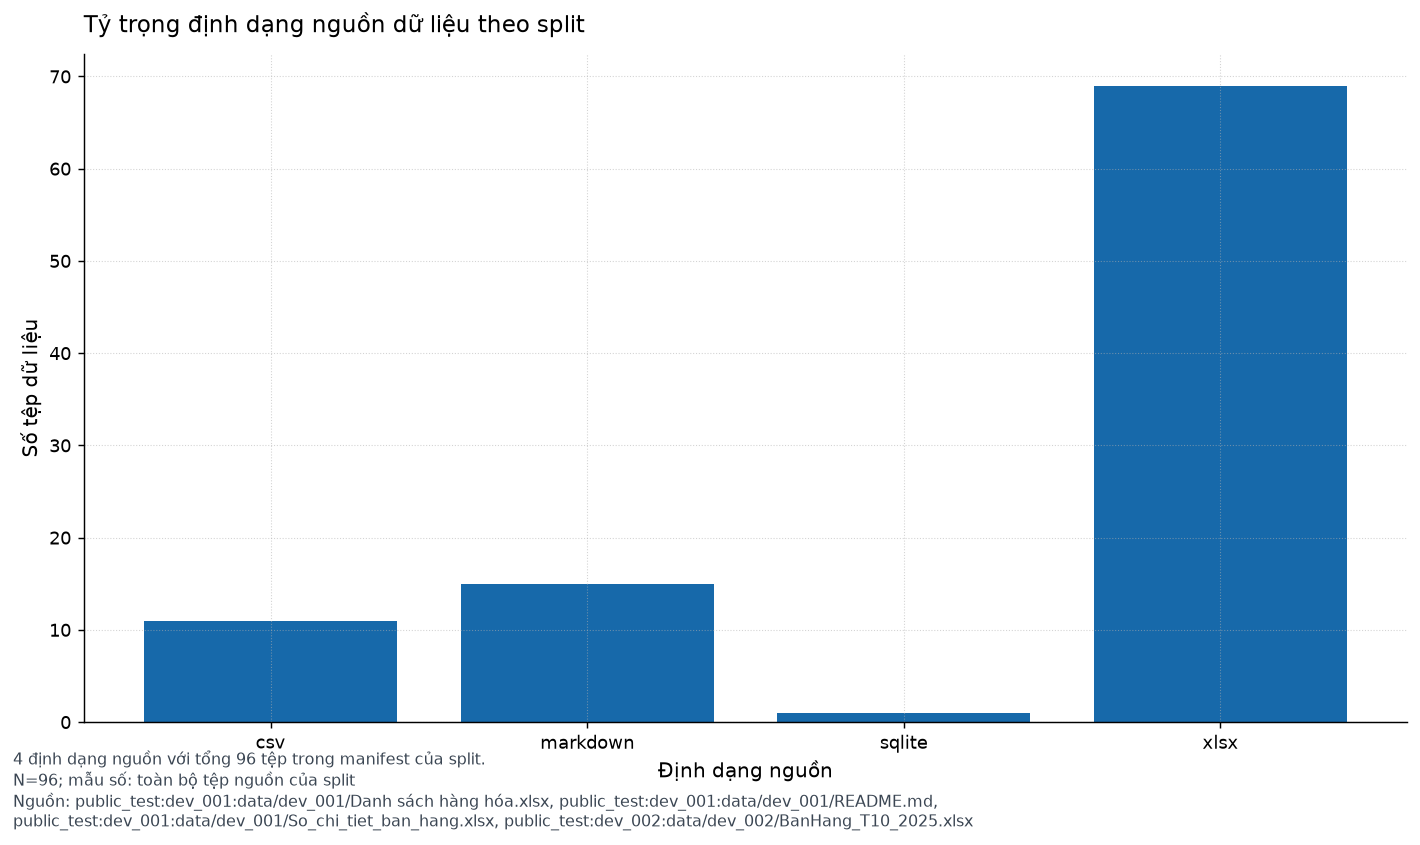


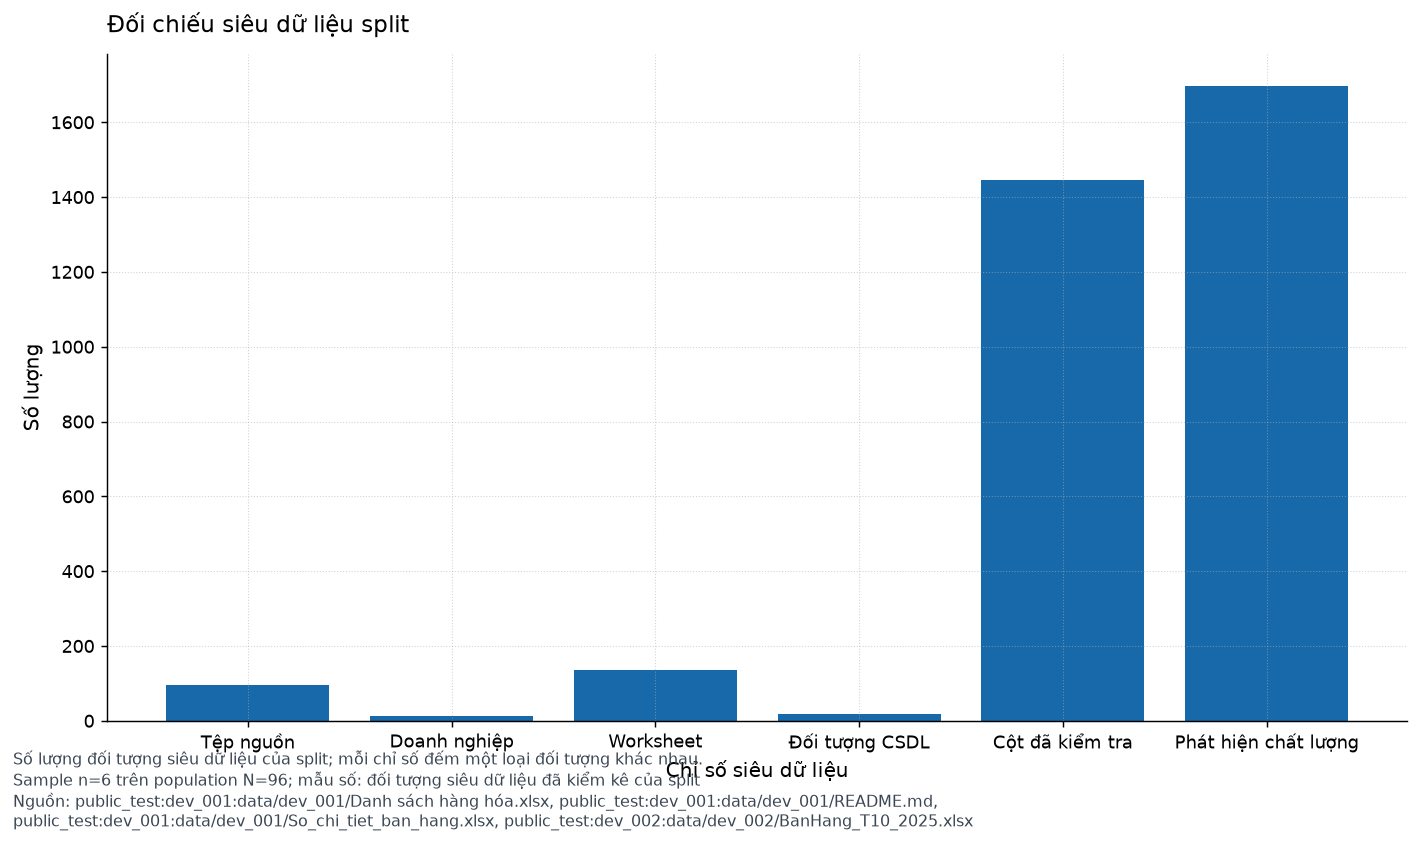

In [6]:
_show_table('TBL01')

_show_figure('INV01', 'public_test', 1)
_show_figure('GLOBAL06', 'public_test', 1)


## 02. Kiểm kê nguồn dữ liệu

**Mục tiêu:** Liệt kê toàn bộ tệp, worksheet và đối tượng CSDL kèm trạng thái đọc, hash và siêu dữ liệu cấu trúc.

**Phương pháp:** Registry kiểm kê gom từ manifest nguồn và registry worksheet/database; mỗi bản ghi gắn content hash của tệp gốc.

**Cách đọc và hạn chế:** Nhiều tệp hơn không đồng nghĩa nhiều giao dịch hơn; tệp trong manifest được đọc ở chế độ chỉ đọc và không bị thay đổi.


source_id,split,business_id,source_type,logical_path,size_bytes,content_hash,status
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx,public_test,dev_001,xlsx,data/dev_001/Danh sách hàng hóa.xlsx,9439,sha256:92ef8720f07501ae4a71b843169d75ffaf2af2a0ed465c64d11df77b50a6f6a5,PASS
public_test:dev_001:data/dev_001/README.md,public_test,dev_001,markdown,data/dev_001/README.md,4672,sha256:8e197003cef404f44a549d6840c4b136adaee1aaa0860156773ef6670df9c6db,PASS
public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx,public_test,dev_001,xlsx,data/dev_001/So_chi_tiet_ban_hang.xlsx,4589213,sha256:a26e9ff3da30989c60eb67be95aa059676f8118678349b9340d2083f0ae53cbc,PASS
public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx,public_test,dev_002,xlsx,data/dev_002/BanHang_T10_2025.xlsx,250626,sha256:6aeb861d4351ad85d8e531eff7c5175c25781d48bc0c180fc2763a6799a678e3,PASS
public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx,public_test,dev_002,xlsx,data/dev_002/BanHang_T11_2025.xlsx,238641,sha256:0ed27e0ea99cb469a1b3beb1c049b6295836370846149944549dfee8eca8169b,PASS
public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx,public_test,dev_002,xlsx,data/dev_002/BanHang_T12_2025.xlsx,244942,sha256:67201a464d55d9ef0491c55b3148081ed44081f3a9daf81818f8567183ab7114,PASS
public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx,public_test,dev_002,xlsx,data/dev_002/BanHang_T1_2025.xlsx,231339,sha256:bce16f907d4321a9a6fd6ad7e3936eabf442237cf1049b0178be6e35ec2368c8,PASS
public_test:dev_002:data/dev_002/BanHang_T1_2026.xlsx,public_test,dev_002,xlsx,data/dev_002/BanHang_T1_2026.xlsx,240741,sha256:9c8d1ec5c8681fe095210d1c3319a23135a636f54149ba401bf9f7197d1e7c19,PASS
public_test:dev_002:data/dev_002/BanHang_T2_2025.xlsx,public_test,dev_002,xlsx,data/dev_002/BanHang_T2_2025.xlsx,217078,sha256:ea9aaa46da316170cc9221c1e842e7113dca0060be1b4ff5e464b819b613d864,PASS
public_test:dev_002:data/dev_002/BanHang_T2_2026.xlsx,public_test,dev_002,xlsx,data/dev_002/BanHang_T2_2026.xlsx,173364,sha256:4309299493f8f33efc7286a1b28924b272dba017d9e88a19f3ed09ea9da6e556,PASS


workbook_path,sheet_name,sheet_state,data_row_count,header_confidence,max_column,has_repeated_header,formula_cell_count
data/dev_001/Danh sách hàng hóa.xlsx,Sheet1,visible,60,1,19,false,0
data/dev_001/So_chi_tiet_ban_hang.xlsx,Sheet1,visible,90854,1,10,false,0
data/dev_002/BanHang_T10_2025.xlsx,DonHang_ChiTiet,visible,5308,1,9,false,0
data/dev_002/BanHang_T11_2025.xlsx,DonHang_ChiTiet,visible,5043,1,9,false,0
data/dev_002/BanHang_T12_2025.xlsx,DonHang_ChiTiet,visible,5185,1,9,false,0
data/dev_002/BanHang_T1_2025.xlsx,DonHang_ChiTiet,visible,4924,1,9,false,0
data/dev_002/BanHang_T1_2026.xlsx,DonHang_ChiTiet,visible,5088,1,9,false,0
data/dev_002/BanHang_T2_2025.xlsx,DonHang_ChiTiet,visible,4593,1,9,false,0
data/dev_002/BanHang_T2_2026.xlsx,DonHang_ChiTiet,visible,3647,1,9,false,0
data/dev_002/BanHang_T3_2025.xlsx,DonHang_ChiTiet,visible,5652,1,9,false,0


database_path,object_type,object_name,primary_key,row_count,column_count,foreign_key_count
data/dev_006/pos.sqlite,table,chi_nhanh,none,1,5,0
data/dev_006/pos.sqlite,table,chi_tiet_don,none,72411,11,0
data/dev_006/pos.sqlite,table,chi_tiet_don_lo,none,72710,6,0
data/dev_006/pos.sqlite,table,chi_tiet_nhap,none,3234,9,0
data/dev_006/pos.sqlite,table,don_hang,none,37833,22,0
data/dev_006/pos.sqlite,table,don_vi_sp,none,83,5,0
data/dev_006/pos.sqlite,table,khach_hang,none,320,18,0
data/dev_006/pos.sqlite,table,lich_su_gia,none,120,4,0
data/dev_006/pos.sqlite,table,lo_hang,none,3234,7,0
data/dev_006/pos.sqlite,table,nha_cung_cap,none,5,10,0



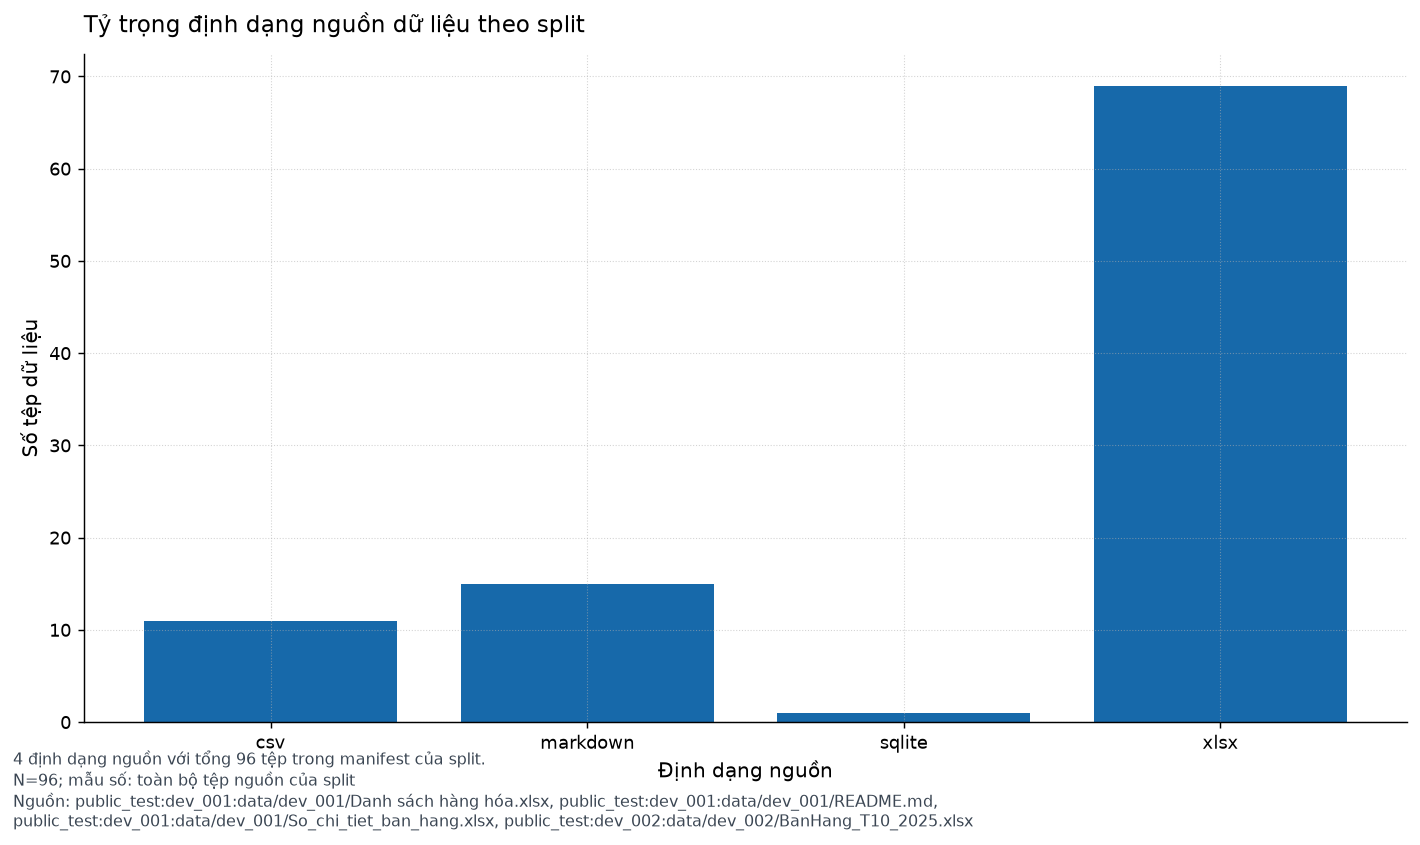


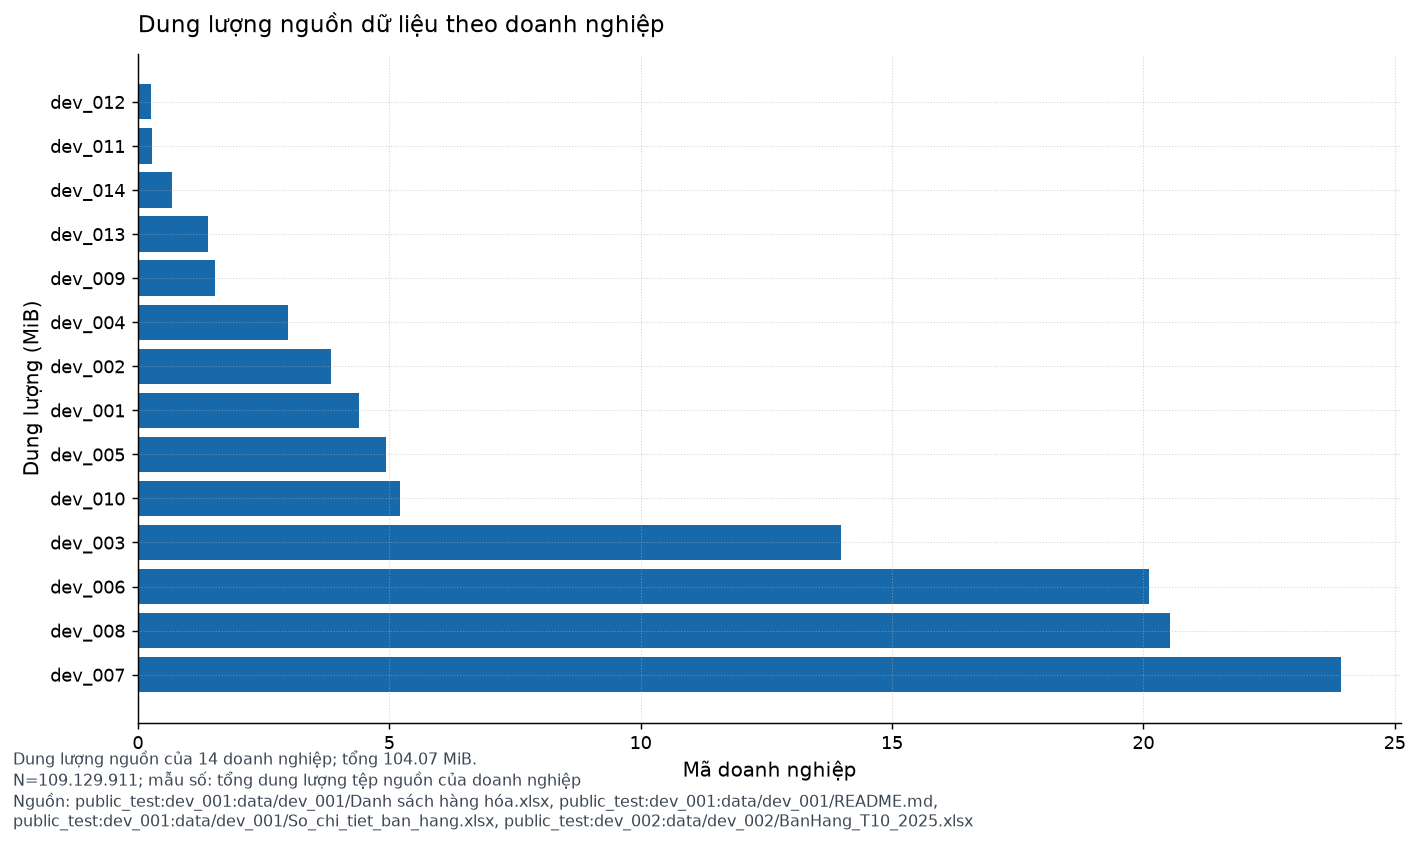


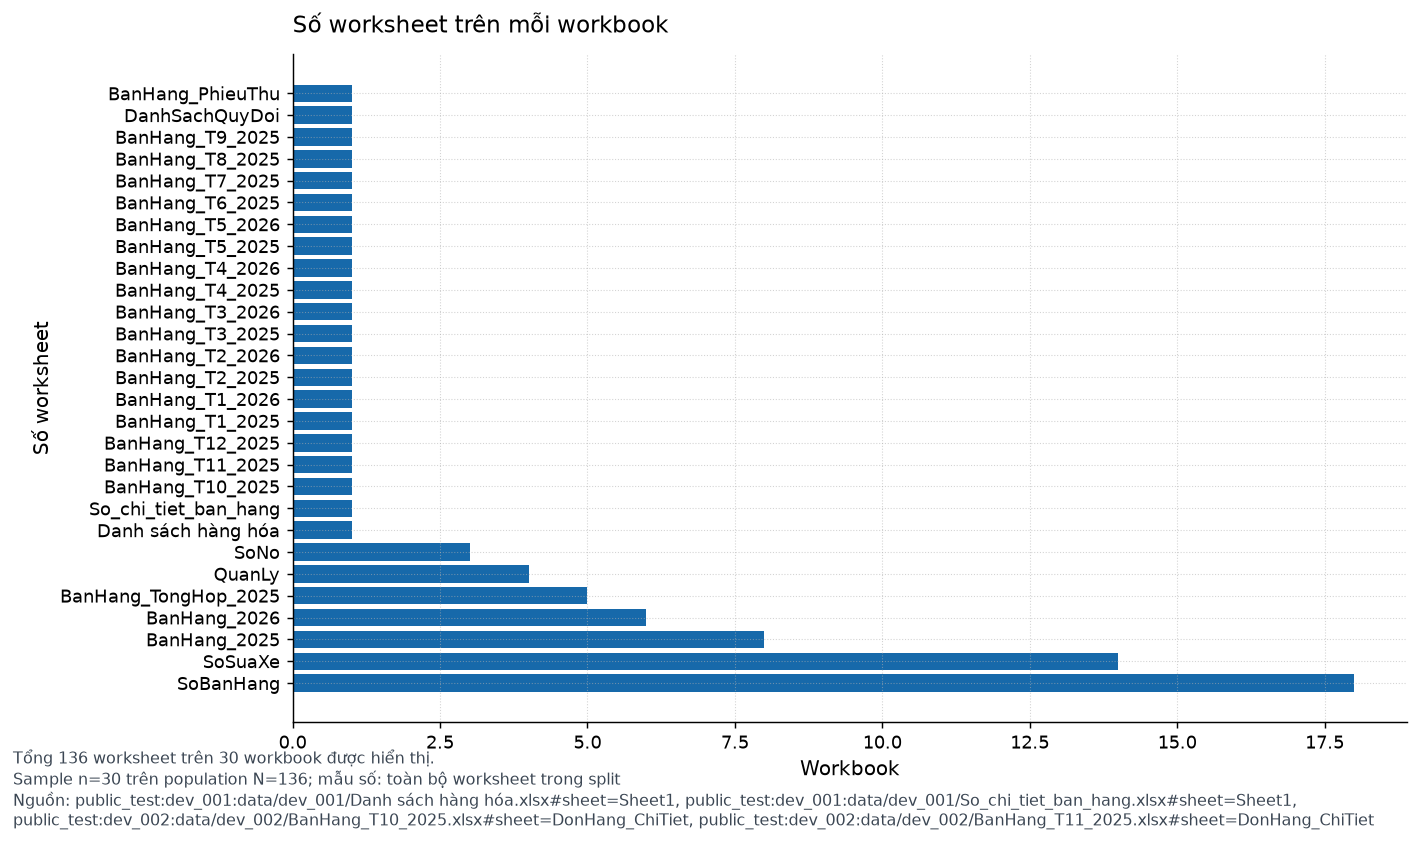


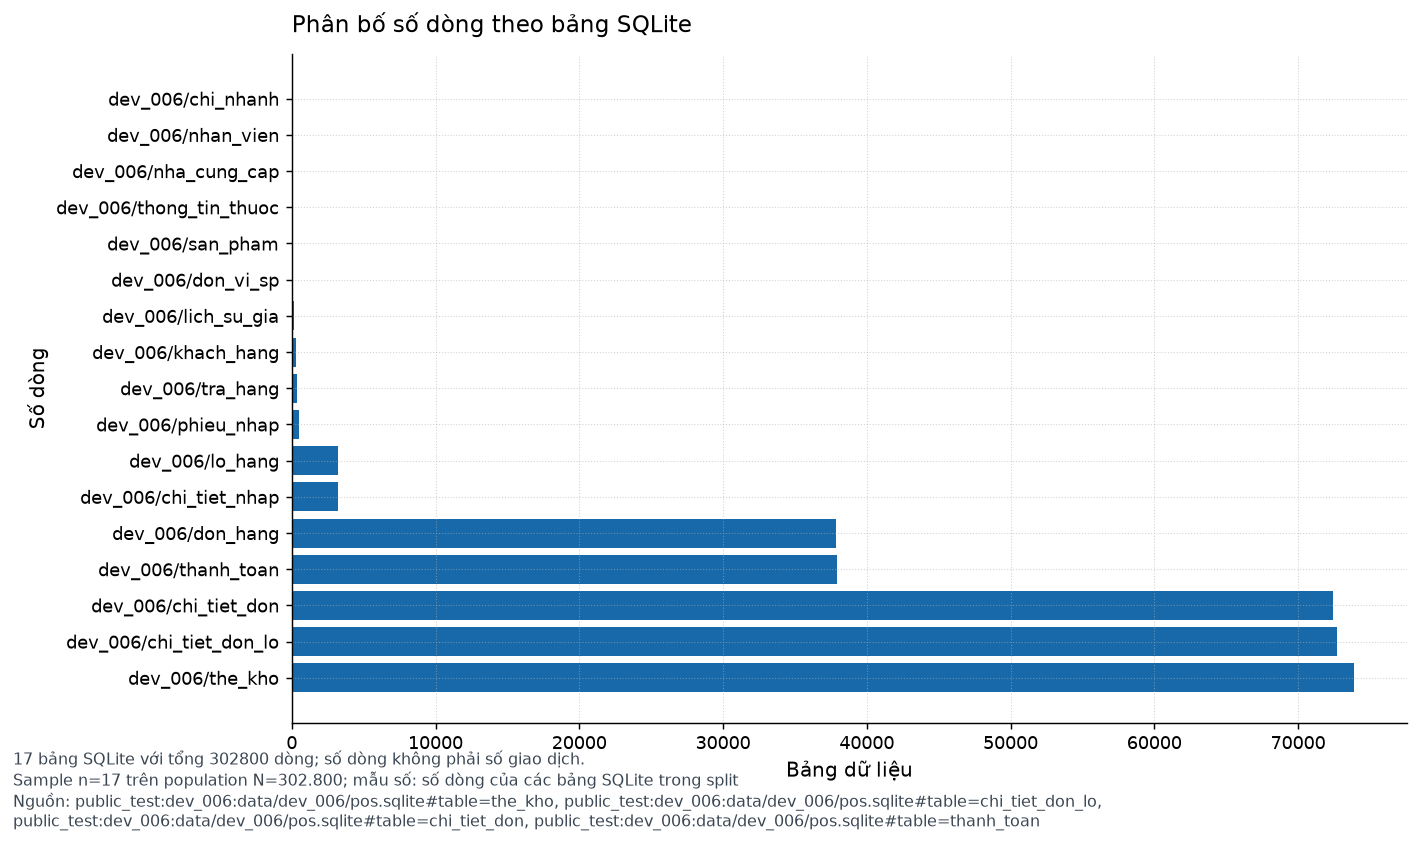

In [7]:
_show_table('TBL02', 'public_test')
_show_table('TBL03', 'public_test')
_show_table('TBL04', 'public_test')

_show_figure('INV01', 'public_test', 1)
_show_figure('INV02', 'public_test', 1)
_show_figure('INV03', 'public_test', 1)
_show_figure('INV04', 'public_test', 1)


## 03. Khám phá schema và mối quan hệ

**Mục tiêu:** Xác định kiểu vật lý và ngữ nghĩa của từng cột, cùng bằng chứng khóa chính và quan hệ giữa các bảng.

**Phương pháp:** Suy luận kiểu dữ liệu trên toàn bộ dòng đã đọc, kết hợp bằng chứng khóa ứng viên và kiểm tra số khóa lệch.

**Cách đọc và hạn chế:** Quan hệ ứng viên chưa được phê duyệt không được dùng để tính chỉ số; phép nối có rủi ro nhân bản bị chặn theo thiết kế.


source_id,column,physical_type,semantic_type,unit,parse_failure_n,business_id,non_null_n,null_n,distinct_n,confidence
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Vị trí,unknown,unknown,none,0,dev_001,0,60,0,0
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Mã hàng hóa,text,text,none,0,dev_001,60,0,60,1
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Định mức tồn tối đa,integer,amount,none,0,dev_001,60,0,1,1
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Được bán trực tiếp,boolean,boolean,none,0,dev_001,60,0,1,1
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Ghi chú,unknown,unknown,none,0,dev_001,0,60,0,0
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Thuộc tính,unknown,unknown,none,0,dev_001,0,60,0,0
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Tên hàng hóa,text,text,none,0,dev_001,60,0,60,1
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Mã barcode,integer,identifier,none,0,dev_001,53,7,53,0.9
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Mô tả sản phẩm,unknown,unknown,none,0,dev_001,0,60,0,0
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Mã HH Liên quan,unknown,unknown,none,0,dev_001,0,60,0,0


left_source,right_source,join_keys,matched_rows,unmatched_left_rows,duplicate_key_left,fanout_factor,status,relation_id,left_grain,right_grain,unmatched_right_rows,duplicate_key_right,risk
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx#sheet=Sheet1,"Tên hàng hóa, Tên hàng hóa",60,0,0,1514.18,CANDIDATE,public_test.dev_001.Sheet1__Tên hàng hóa_Tên hàng hóa__Sheet1,one row per Sheet1,one row per Sheet1,14,90223,duplicate_keys_may_cause_fanout
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx#sheet=Sheet1,"Đơn vị tính, Đơn vị tính",11,0,49,1514.18,CANDIDATE,public_test.dev_001.Sheet1__Đơn vị tính_Đơn vị tính__Sheet1,one row per Sheet1,one row per Sheet1,5,90281,duplicate_keys_may_cause_fanout
public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet,public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet,"Mã đơn hàng, Mã đơn hàng",1,3302,1970,0.95,CANDIDATE,public_test.dev_002.DonHang_ChiTiet__Mã đơn hàng_Mã đơn hàng__DonHang_ChiTiet,one row per DonHang_ChiTiet,one row per DonHang_ChiTiet,3122,1886,duplicate_keys_may_cause_fanout
public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet,public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet,"Ngày đặt hàng, Ngày đặt hàng",1,62,5210,0.95,CANDIDATE,public_test.dev_002.DonHang_ChiTiet__Ngày đặt hàng_Ngày đặt hàng__DonHang_ChiTiet,one row per DonHang_ChiTiet,one row per DonHang_ChiTiet,60,4948,duplicate_keys_may_cause_fanout
public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet,public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet,"Mã đơn hàng, Mã đơn hàng",1,3302,1970,0.9768,CANDIDATE,public_test.dev_002.DonHang_ChiTiet__Mã đơn hàng_Mã đơn hàng__DonHang_ChiTiet,one row per DonHang_ChiTiet,one row per DonHang_ChiTiet,3209,1940,duplicate_keys_may_cause_fanout
public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet,public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet,"Ngày đặt hàng, Ngày đặt hàng",1,62,5210,0.9768,CANDIDATE,public_test.dev_002.DonHang_ChiTiet__Ngày đặt hàng_Ngày đặt hàng__DonHang_ChiTiet,one row per DonHang_ChiTiet,one row per DonHang_ChiTiet,62,5087,duplicate_keys_may_cause_fanout
public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet,public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet,"Mã đơn hàng, Mã đơn hàng",1,3302,1970,0.9276,CANDIDATE,public_test.dev_002.DonHang_ChiTiet__Mã đơn hàng_Mã đơn hàng__DonHang_ChiTiet,one row per DonHang_ChiTiet,one row per DonHang_ChiTiet,3069,1819,duplicate_keys_may_cause_fanout
public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet,public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet,"Ngày đặt hàng, Ngày đặt hàng",1,62,5210,0.9276,CANDIDATE,public_test.dev_002.DonHang_ChiTiet__Ngày đặt hàng_Ngày đặt hàng__DonHang_ChiTiet,one row per DonHang_ChiTiet,one row per DonHang_ChiTiet,62,4826,duplicate_keys_may_cause_fanout
public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet,public_test:dev_002:data/dev_002/BanHang_T1_2026.xlsx#sheet=DonHang_ChiTiet,"Mã đơn hàng, Mã đơn hàng",1,3302,1970,0.9585,CANDIDATE,public_test.dev_002.DonHang_ChiTiet__Mã đơn hàng_Mã đơn hàng__DonHang_ChiTiet,one row per DonHang_ChiTiet,one row per DonHang_ChiTiet,3188,1864,duplicate_keys_may_cause_fanout
public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet,public_test:dev_002:data/dev_002/BanHang_T1_2026.xlsx#sheet=DonHang_ChiTiet,"Ngày đặt hàng, Ngày đặt hàng",1,62,5210,0.9585,CANDIDATE,public_test.dev_002.DonHang_ChiTiet__Ngày đặt hàng_Ngày đặt hàng__DonHang_ChiTiet,one row per DonHang_ChiTiet,one row per DonHang_ChiTiet,62,4990,duplicate_keys_may_cause_fanout



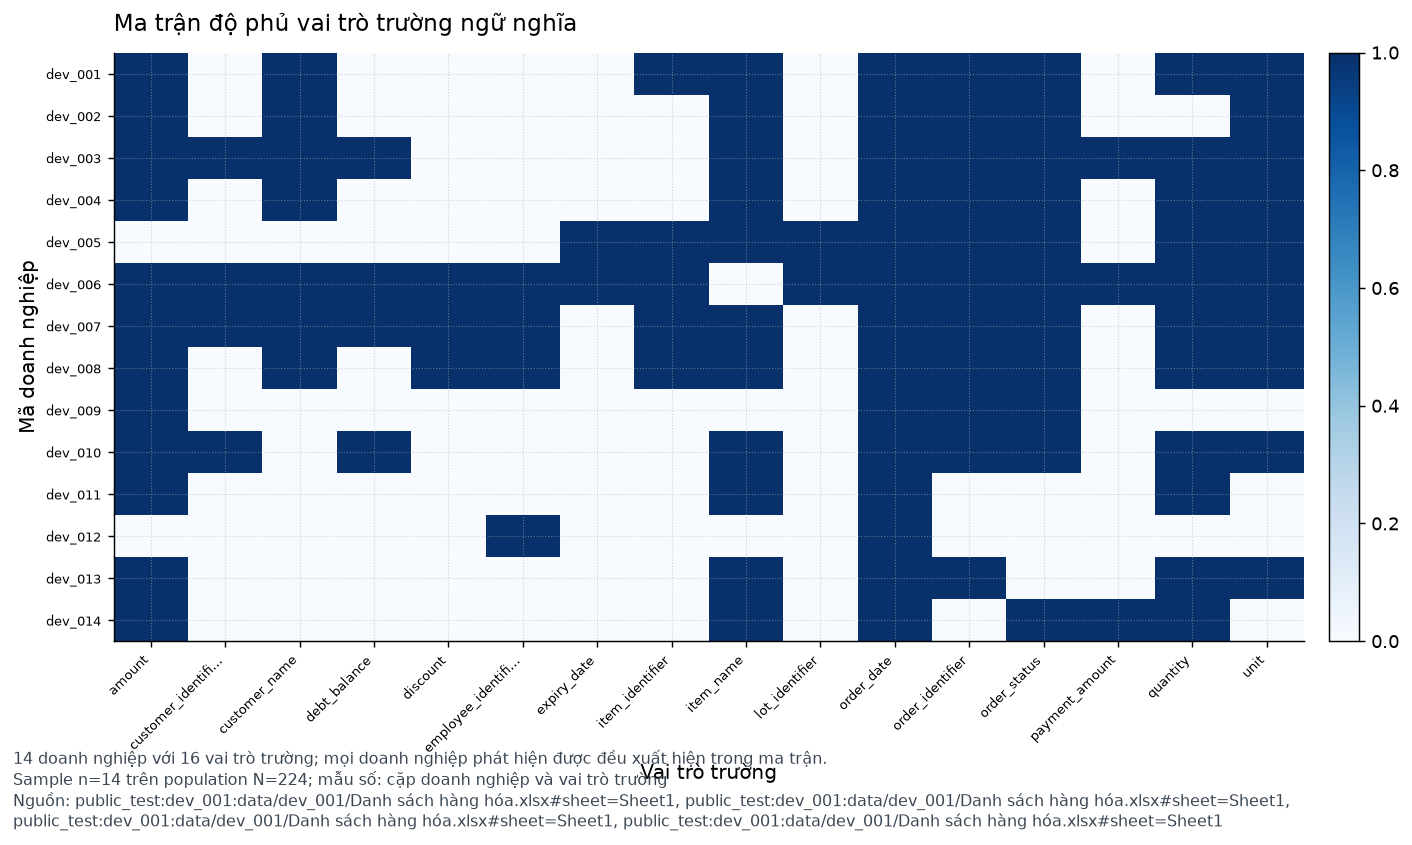


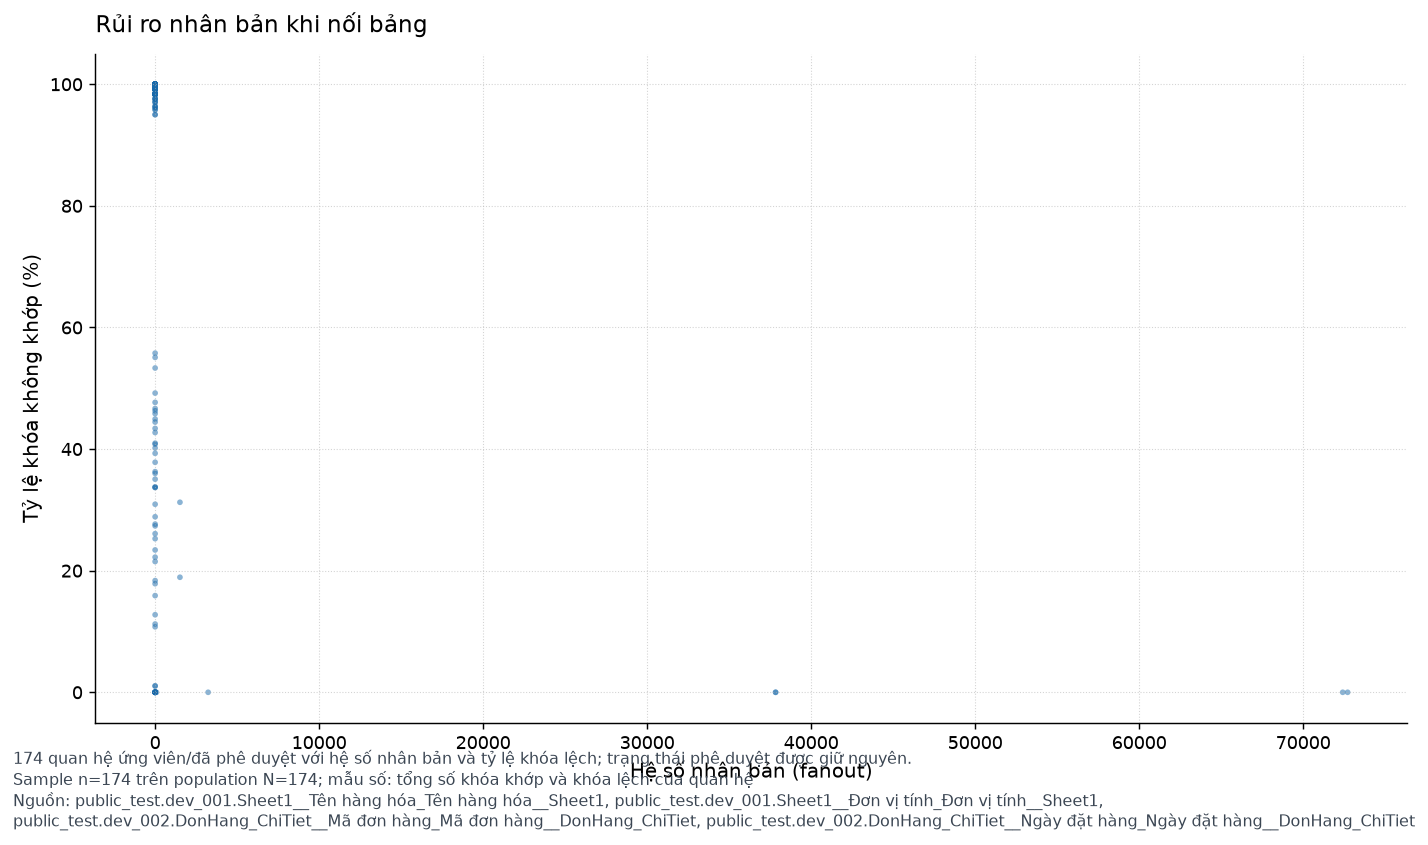

In [8]:
_show_table('TBL05', 'public_test')
_show_table('TBL12', 'public_test')

_show_figure('GLOBAL02', 'public_test', 1)
_show_figure('QUAL07', 'public_test', 1)


## 04. Chất lượng dữ liệu

**Mục tiêu:** Đo mức thiếu dữ liệu, trùng lặp, vi phạm quy tắc và mức độ phát hiện theo từng nguồn, kèm mẫu số rõ ràng.

**Phương pháp:** Mọi tỷ lệ đều chia cho mẫu số của chính trường hoặc chính quy tắc được hồ sơ; thiếu dữ liệu có cấu trúc tách riêng khỏi khoảng trống thực.

**Cách đọc và hạn chế:** Cờ thiếu dữ liệu và cờ trùng lặp là tín hiệu thống kê, chưa được xác định là bản ghi lỗi nếu chưa có đối chiếu rulebook.


source_id,column,n_missing,n_total,missing_ratio,null_kind,business_id,co_missing_with
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Vị trí,60,60,1,blank_or_not_applicable,dev_001,"Ghi chú, Thuộc tính, Mô tả sản phẩm, Mã HH Liên quan, Bảo hành, Trọng lượng, Mẫu ghi chú, Hình ảnh"
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Ghi chú,60,60,1,structural_missing,dev_001,"Vị trí, Thuộc tính, Mô tả sản phẩm, Mã HH Liên quan, Bảo hành, Trọng lượng, Mẫu ghi chú, Hình ảnh"
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Thuộc tính,60,60,1,blank_or_not_applicable,dev_001,"Vị trí, Ghi chú, Mô tả sản phẩm, Mã HH Liên quan, Bảo hành, Trọng lượng, Mẫu ghi chú, Hình ảnh"
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Mã barcode,7,60,0.116667,unknown,dev_001,"Vị trí, Ghi chú, Thuộc tính, Mô tả sản phẩm, Mã HH Liên quan, Bảo hành, Trọng lượng, Mẫu ghi chú"
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Mô tả sản phẩm,60,60,1,blank_or_not_applicable,dev_001,"Vị trí, Ghi chú, Thuộc tính, Mã HH Liên quan, Bảo hành, Trọng lượng, Mẫu ghi chú, Hình ảnh"
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Mã HH Liên quan,60,60,1,blank_or_not_applicable,dev_001,"Vị trí, Ghi chú, Thuộc tính, Mô tả sản phẩm, Bảo hành, Trọng lượng, Mẫu ghi chú, Hình ảnh"
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Bảo hành,60,60,1,blank_or_not_applicable,dev_001,"Vị trí, Ghi chú, Thuộc tính, Mô tả sản phẩm, Mã HH Liên quan, Trọng lượng, Mẫu ghi chú, Hình ảnh"
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Trọng lượng,60,60,1,blank_or_not_applicable,dev_001,"Vị trí, Ghi chú, Thuộc tính, Mô tả sản phẩm, Mã HH Liên quan, Bảo hành, Mẫu ghi chú, Hình ảnh"
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Mẫu ghi chú,60,60,1,structural_missing,dev_001,"Vị trí, Ghi chú, Thuộc tính, Mô tả sản phẩm, Mã HH Liên quan, Bảo hành, Trọng lượng, Hình ảnh"
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,Hình ảnh,60,60,1,blank_or_not_applicable,dev_001,"Vị trí, Ghi chú, Thuộc tính, Mô tả sản phẩm, Mã HH Liên quan, Bảo hành, Trọng lượng, Mẫu ghi chú"


source_id,duplicate_class,n_duplicate_rows,total_n,explanation,business_id,key_columns,n_distinct_keys
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,exact_row,0,60,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,dev_001,all columns,60
public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1,business_key,0,60,rows sharing the candidate business key; duplicates are valid when the grain is line-item and invalid when the grain is order,dev_001,Mã hàng hóa,60
public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx#sheet=Sheet1,exact_row,0,90851,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,dev_001,all columns,90851
public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet,exact_row,24,5305,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,dev_002,all columns,5281
public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet,exact_row,26,5040,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,dev_002,all columns,5014
public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet,exact_row,26,5182,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,dev_002,all columns,5156
public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet,exact_row,21,4921,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,dev_002,all columns,4900
public_test:dev_002:data/dev_002/BanHang_T1_2026.xlsx#sheet=DonHang_ChiTiet,exact_row,23,5085,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,dev_002,all columns,5062
public_test:dev_002:data/dev_002/BanHang_T2_2025.xlsx#sheet=DonHang_ChiTiet,exact_row,22,4590,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,dev_002,all columns,4568
public_test:dev_002:data/dev_002/BanHang_T2_2026.xlsx#sheet=DonHang_ChiTiet,exact_row,15,3644,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,dev_002,all columns,3629


source_id,column,rule_id,invalid_count,denominator,evidence,business_id,invalid_ratio,severity,sample_masked
public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet,Ngày đặt hàng,VAL.DATE.PARSE,25,5273,value could not be interpreted as a calendar date,dev_002,0.004741,medium,N***********g; N***********g; N***********g; N***********g; N***********g
public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet,Giá sản phẩm,VAL.NUM.PARSE,25,5273,non-numeric token found in a column typed as a numeric measure,dev_002,0.004741,medium,G**********m; G**********m; G**********m; G**********m; G**********m
public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet,Ngày đặt hàng,VAL.DATE.PARSE,27,5009,value could not be interpreted as a calendar date,dev_002,0.00539,medium,N***********g; N***********g; N***********g; N***********g; N***********g
public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet,Giá sản phẩm,VAL.NUM.PARSE,27,5009,non-numeric token found in a column typed as a numeric measure,dev_002,0.00539,medium,G**********m; G**********m; G**********m; G**********m; G**********m
public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet,Ngày đặt hàng,VAL.DATE.PARSE,27,5150,value could not be interpreted as a calendar date,dev_002,0.005243,medium,N***********g; N***********g; N***********g; N***********g; N***********g
public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet,Giá sản phẩm,VAL.NUM.PARSE,27,5150,non-numeric token found in a column typed as a numeric measure,dev_002,0.005243,medium,G**********m; G**********m; G**********m; G**********m; G**********m
public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet,Ngày đặt hàng,VAL.DATE.PARSE,22,4889,value could not be interpreted as a calendar date,dev_002,0.0045,medium,N***********g; N***********g; N***********g; N***********g; N***********g
public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet,Giá sản phẩm,VAL.NUM.PARSE,22,4889,non-numeric token found in a column typed as a numeric measure,dev_002,0.0045,medium,G**********m; G**********m; G**********m; G**********m; G**********m
public_test:dev_002:data/dev_002/BanHang_T1_2026.xlsx#sheet=DonHang_ChiTiet,Ngày đặt hàng,VAL.DATE.PARSE,24,5053,value could not be interpreted as a calendar date,dev_002,0.00475,medium,N***********g; N***********g; N***********g; N***********g; N***********g
public_test:dev_002:data/dev_002/BanHang_T1_2026.xlsx#sheet=DonHang_ChiTiet,Giá sản phẩm,VAL.NUM.PARSE,24,5053,non-numeric token found in a column typed as a numeric measure,dev_002,0.00475,medium,G**********m; G**********m; G**********m; G**********m; G**********m


finding_id,severity,domain,business_id,count,denominator,evidence,status,source_id,field,ratio,hypothesis,alternative_explanation,verification
DUP.public_test:dev_005:data/dev_005/BanHang_Thang01_2025.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2321,4957,exact_row duplicates=2321 distinct_keys=2636,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang01_2025.xlsx#sheet=DonHang_ChiTiet,none,0.468227,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang01_2026.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2360,4992,exact_row duplicates=2360 distinct_keys=2632,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang01_2026.xlsx#sheet=DonHang_ChiTiet,none,0.472756,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang02_2025.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,1999,4312,exact_row duplicates=1999 distinct_keys=2313,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang02_2025.xlsx#sheet=DonHang_ChiTiet,none,0.46359,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang02_2026.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2019,4341,exact_row duplicates=2019 distinct_keys=2322,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang02_2026.xlsx#sheet=DonHang_ChiTiet,none,0.4651,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang03_2025.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2143,4546,exact_row duplicates=2143 distinct_keys=2403,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang03_2025.xlsx#sheet=DonHang_ChiTiet,none,0.471403,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang03_2026.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2217,4742,exact_row duplicates=2217 distinct_keys=2525,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang03_2026.xlsx#sheet=DonHang_ChiTiet,none,0.467524,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang04_2025.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2063,4445,exact_row duplicates=2063 distinct_keys=2382,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang04_2025.xlsx#sheet=DonHang_ChiTiet,none,0.464117,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang04_2026.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2170,4666,exact_row duplicates=2170 distinct_keys=2496,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang04_2026.xlsx#sheet=DonHang_ChiTiet,none,0.465066,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated e


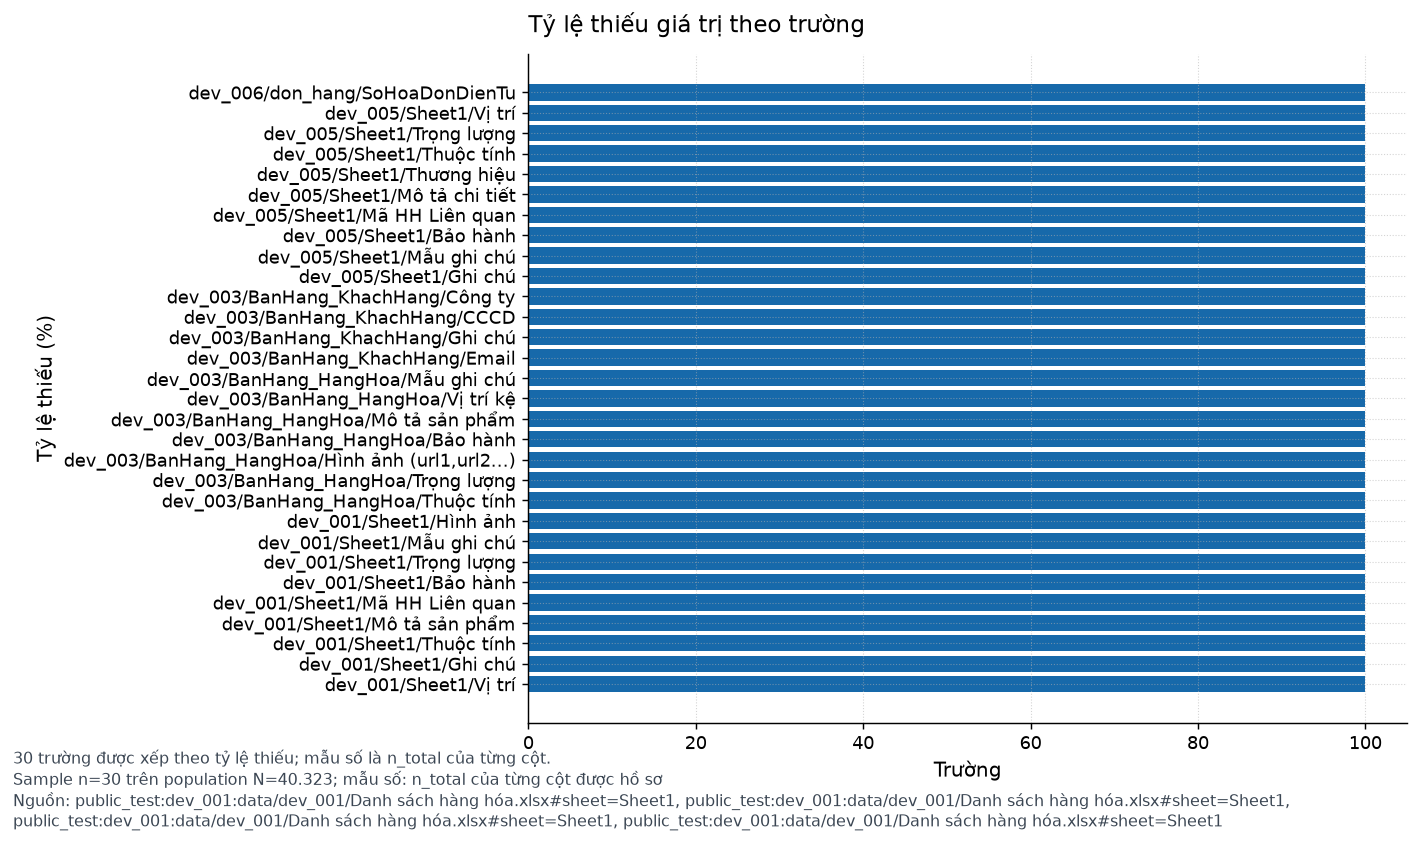


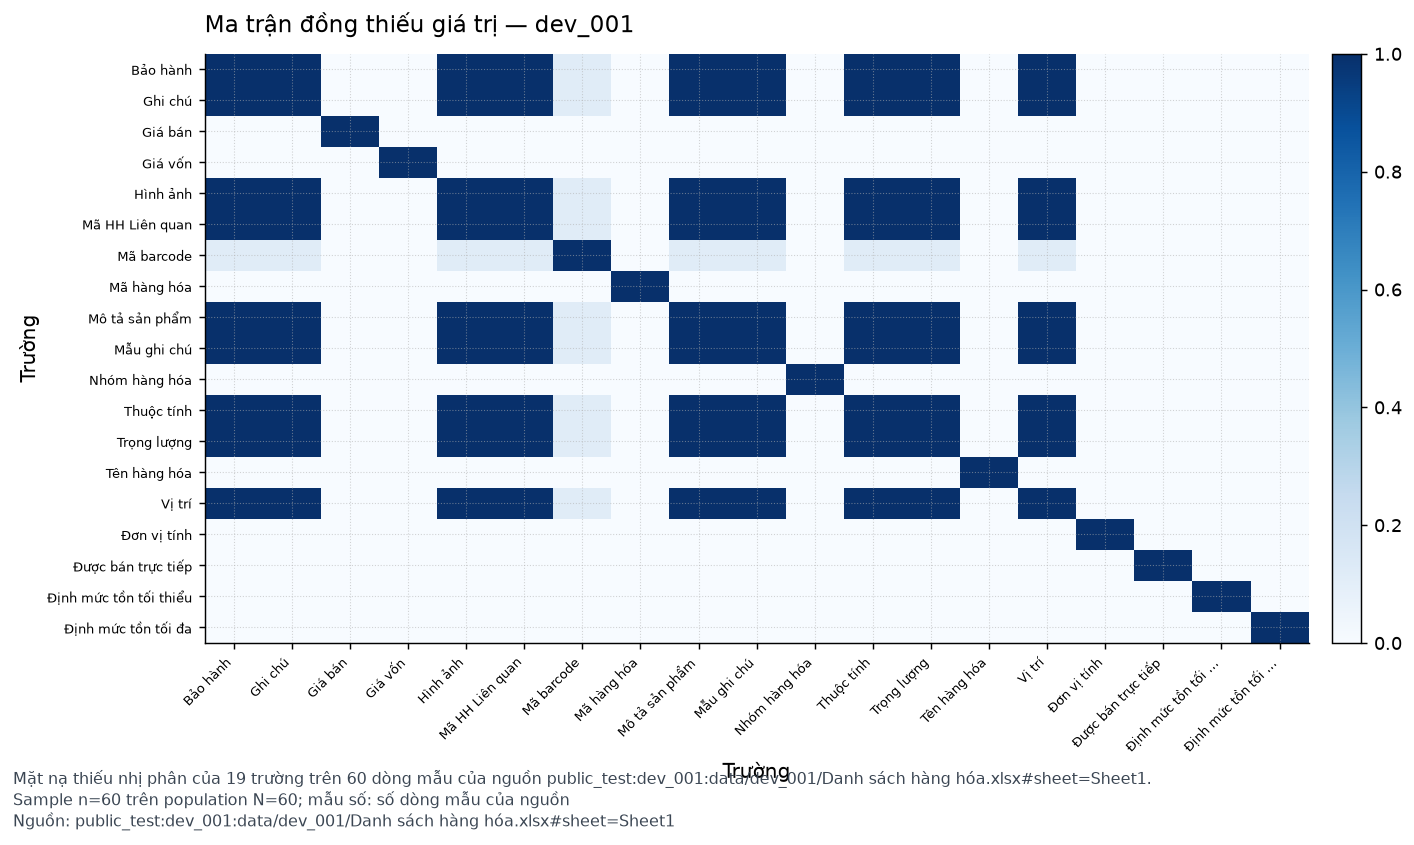


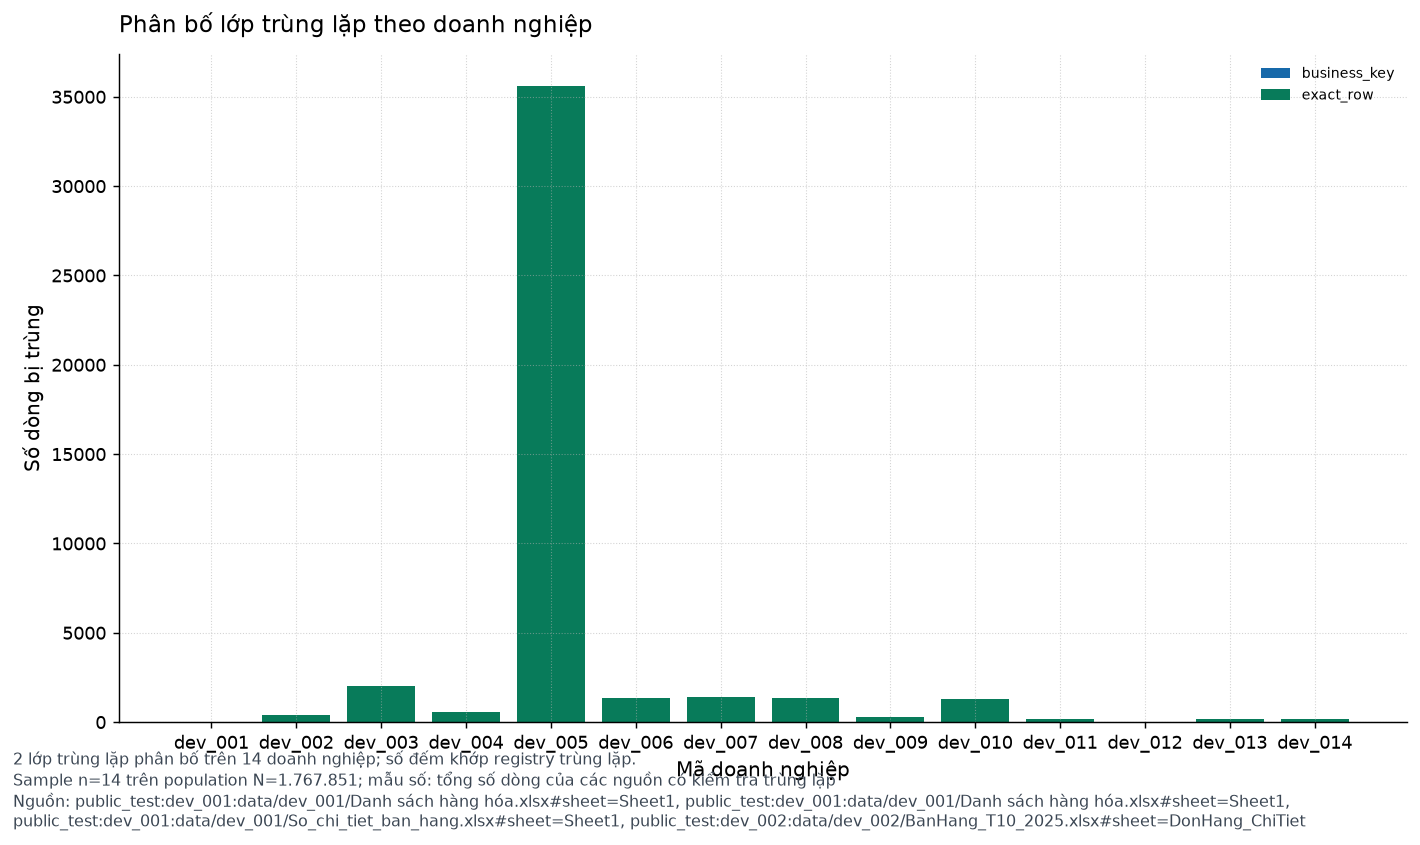


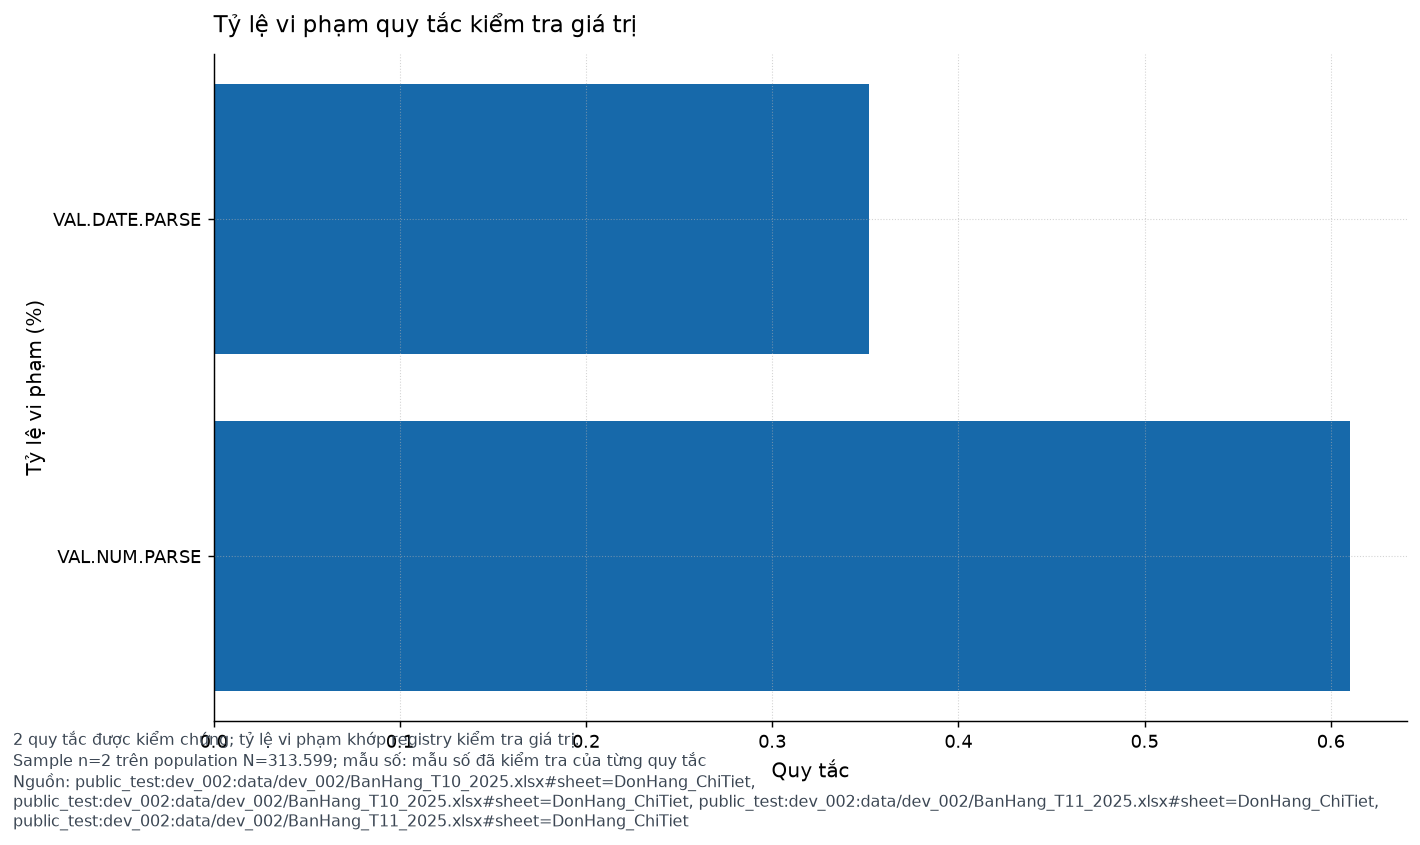

#### Thẻ chuyện `CAT01` — dev_001 (public_test)

1. **Mục tiêu:** Nhóm giá trị nào chiếm ưu thế trong một trường phân loại?
2. **Bối cảnh:** split = public_test; doanh nghiệp = dev_001; nguồn = ('public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = frequency_per_category; quy tắc lọc = count(category) với mẫu số n_valid; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 60
   - n_valid = 60
   - đơn vị = row
   - phương pháp = frequency_per_category
   - công thức = count(category) với mẫu số n_valid
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261116T115457Z_092a846e/analysis/public_test/dev_001/CAT01.png
6. **Nhận xét:**
   - Chưa đủ bằng chứng hoặc điều kiện kiểm chứng để đưa ra nhận xét.
7. **Ý nghĩa:** Mô tả cấu trúc phân phối danh mục kèm mẫu số rõ ràng.
8. **Hạn chế:**
   - association_is_not_causation
   - coverage_and_method_are_reported_with_every_figure
9. **Kết luận:** Kết luận chỉ được ghi khi số liệu kiểm chứng tồn tại; nếu thiếu bằng chứng thì ghi 'Chưa đủ dữ liệu hoặc điều kiện kiểm chứng để đưa ra kết luận.'

*Mức tin cậy: NEEDS_REVIEW; trạng thái: PARTIAL.*

#### Thẻ chuyện `CAT02` — dev_001 (public_test)

1. **Mục tiêu:** Đầu và đuôi phân phối danh mục khác nhau thế nào?
2. **Bối cảnh:** split = public_test; doanh nghiệp = dev_001; nguồn = ('public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = top_k_with_others_bucket; quy tắc lọc = top-k danh mục theo số đếm + Others, tổng bằng n_valid; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 60
   - n_valid = 60
   - đơn vị = row
   - phương pháp = top_k_with_others_bucket
   - công thức = top-k danh mục theo số đếm + Others, tổng bằng n_valid
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261116T115457Z_092a846e/analysis/public_test/dev_001/CAT02.png
6. **Nhận xét:**
   - Chưa đủ bằng chứng hoặc điều kiện kiểm chứng để đưa ra nhận xét.
7. **Ý nghĩa:** Tạo nhóm Others có kiểm soát mà vẫn bảo toàn tổng số đếm.
8. **Hạn chế:**
   - association_is_not_causation
   - coverage_and_method_are_reported_with_every_figure
9. **Kết luận:** Kết luận chỉ được ghi khi số liệu kiểm chứng tồn tại; nếu thiếu bằng chứng thì ghi 'Chưa đủ dữ liệu hoặc điều kiện kiểm chứng để đưa ra kết luận.'

*Mức tin cậy: NEEDS_REVIEW; trạng thái: PARTIAL.*

#### Thẻ chuyện `CAT03` — dev_001 (public_test)

1. **Mục tiêu:** Thành phần danh mục chia đều thế nào?
2. **Bối cảnh:** split = public_test; doanh nghiệp = dev_001; nguồn = ('public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = category_share_of_valid; quy tắc lọc = count(category) / n_valid; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 60
   - n_valid = 60
   - đơn vị = percent
   - phương pháp = category_share_of_valid
   - công thức = count(category) / n_valid
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261116T115457Z_092a846e/analysis/public_test/dev_001/CAT03.png
6. **Nhận xét:**
   - Chưa đủ bằng chứng hoặc điều kiện kiểm chứng để đưa ra nhận xét.
7. **Ý nghĩa:** Trình bày tỷ trọng với mẫu số nhất quán.
8. **Hạn chế:**
   - association_is_not_causation
   - coverage_and_method_are_reported_with_every_figure
9. **Kết luận:** Kết luận chỉ được ghi khi số liệu kiểm chứng tồn tại; nếu thiếu bằng chứng thì ghi 'Chưa đủ dữ liệu hoặc điều kiện kiểm chứng để đưa ra kết luận.'

*Mức tin cậy: NEEDS_REVIEW; trạng thái: PARTIAL.*

#### Thẻ chuyện `GLOBAL01` — global (public_test)

1. **Mục tiêu:** Doanh nghiệp dùng định dạng lưu trữ nào?
2. **Bối cảnh:** split = public_test; doanh nghiệp = global; nguồn = ('public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx', 'public_test:dev_001:data/dev_001/README.md', 'public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T1_2026.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T2_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T2_2026.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T3_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T3_2026.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T4_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T4_2026.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T5_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T5_2026.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T6_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T7_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T8_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T9_2025.xlsx', 'public_test:dev_002:data/dev_002/DanhSachQuyDoi.xlsx', 'public_test:d

In [9]:
_show_table('TBL06', 'public_test')
_show_table('TBL07', 'public_test')
_show_table('TBL08', 'public_test')
_show_table('TBL19', 'public_test')

_show_figure('QUAL01', 'public_test', 1)
_show_figure('QUAL02', 'public_test', 1)
_show_figure('QUAL04', 'public_test', 1)
_show_figure('QUAL05', 'public_test', 1)

display(Markdown(run.story_cards_markdown(
    'public_test'
)[:5200]))


## 05. Phân tích định lượng

**Mục tiêu:** Mô tả phân phối các đo lường định lượng trên toàn bộ dân số hợp lệ, kèm thống kê bền vững và cờ ngoại lệ theo IQR.

**Phương pháp:** Tính quantile, MAD, lệch và kurtosis trên toàn bộ quan sát hợp lệ; ngưỡng ngoại lệ IQR chỉ gắn cờ, không tự động loại bỏ.

**Cách đọc và hạn chế:** Kiểu vật lý không bảo đảm ngữ nghĩa đo lường; cột định danh dạng số được xử lý riêng và không đưa vào phân tích phân phối đo lường.


In [ ]:
_show_table('TBL09', 'public_test')

_show_figure('NUM01', 'public_test', 2)
_show_figure('NUM02', 'public_test', 1)
_show_figure('NUM06', 'public_test', 1)
_show_figure('NUM08', 'public_test', 1)

display(Markdown(run.story_cards_markdown(
    'public_test'
)[:5200]))


## 06. Phân tích phân loại

**Mục tiêu:** Khảo sát phân phối tần suất của các trường phân loại, giữ nguyên nhóm Others và ghi nhận ứng viên bí danh thay vì tự gộp.

**Phương pháp:** Đếm tần suất theo giá trị đã chuẩn hóa, sắp xếp theo tần suất giảm dần và ghi rõ phạm vi quan sát của mỗi trường.

**Cách đọc và hạn chế:** Cao độ lớp phụ thuộc quy tắc chuẩn hóa giá trị; các giá trị tương tự nhau về nghĩa chỉ được báo cáo là ứng viên, không tự ý hợp nhất.


In [ ]:
_show_table('TBL10', 'public_test')

_show_figure('CAT01', 'public_test', 2)
_show_figure('CAT02', 'public_test', 1)
_show_figure('CAT03', 'public_test', 1)

display(Markdown(run.story_cards_markdown(
    'public_test'
)[:5200]))


## 07. Tương quan và phân tích đa biến

**Mục tiêu:** Đo mức liên hệ giữa các đo lường và các trường phân loại trên cùng grain, chỉ dùng các phép nối đã được phê duyệt.

**Phương pháp:** Tính Pearson, Spearman, Kendall, Cramér V và bảng chéo trong phạm vi cùng một nguồn hoặc phép nối không nhân bản.

**Cách đọc và hạn chế:** Tương quan không phải quan hệ nhân quả; phép nối ứng viên chỉ được hiển thị để đánh giá rủi ro nhân bản, không dùng cho tính chỉ số.


In [ ]:
_show_table('TBL12', 'public_test')

_show_figure('REL03', 'public_test', 1)
_show_figure('REL06', 'public_test', 1)
_show_figure('REL08', 'public_test', 1)
_show_figure('REL09', 'public_test', 1)
_show_figure('REL10', 'public_test', 1)

display(Markdown(run.story_cards_markdown(
    'public_test'
)[:5200]))


## 08. Hồ sơ thời gian và lịch

**Mục tiêu:** Xác định ngữ nghĩa trường ngày, khoảng phủ thời gian, số ngày có hoạt động và các kỳ bị thiếu theo lịch của split.

**Phương pháp:** Đọc và chuẩn hóa giá trị ngày theo quy tắc từng split, đối chiếu với lịch và báo cáo khoảng phủ theo doanh nghiệp.

**Cách đọc và hạn chế:** Mỗi trường ngày giữ vai trò sự kiện riêng nên các khoảng phủ không thể so sánh trực tiếp; thiếu dữ liệu theo kỳ không được coi là giá trị bằng không.


In [ ]:
_show_table('TBL11', 'public_test')

_show_figure('TIME01', 'public_test', 1)
_show_figure('TIME02', 'public_test', 1)
_show_figure('TIME03', 'public_test', 1)
_show_figure('TIME07', 'public_test', 1)

display(Markdown(run.story_cards_markdown(
    'public_test'
)[:5200]))


## 09. Phân tích theo từng doanh nghiệp

**Mục tiêu:** Trình bày hồ sơ, phân loại ngành và các chỉ số kinh doanh đủ điều kiện của từng doanh nghiệp trong split.

**Phương pháp:** Chỉ số được tính trên grain đã xác định, tuân thủ quy tắc trạng thái của rulebook split và chỉ hiển thị khi doanh nghiệp đủ điều kiện.

**Cách đọc và hạn chế:** Doanh nghiệp thiếu điều kiện bị ghi trạng thái rõ ràng, không được thay bằng số liệu của doanh nghiệp khác để lấp chỗ trống.


In [ ]:
_show_table('TBL13', 'public_test')
_show_table('TBL14', 'public_test')


## 10. Giá trị đơn hàng và ngoại lệ tại dev_001

**Mục tiêu:** Giá trị tiền hàng điển hình của một đơn là bao nhiêu? Các đơn lớn nằm ở đâu trong phân phối?

**Phương pháp:** Tại dev_001, khóa là mã đơn và doanh thu là tổng Thành tiền các dòng cùng đơn. Tại dev_009, khóa là mã hóa đơn và doanh thu lấy từ Giá trị hàng. Bảng kiểm tra ghi số dòng thiếu mã, dòng trùng y hệt và số đơn thiếu dữ liệu hoặc mâu thuẫn. Giữ đơn hoàn thành và đang giao khi tính doanh thu. Xác định ngoại lệ ở cấp đơn bằng hai ngưỡng Q1 − 1,5 × IQR và Q3 + 1,5 × IQR, với IQR = Q3 − Q1.

**Cách đọc và hạn chế:** Dòng thiếu mã được loại khỏi phân tích đơn vì chưa thể xác minh thuộc đơn nào. Cờ IQR dùng để kiểm tra lại chứng từ. Các đơn ngoài ngưỡng vẫn góp vào thống kê.


In [ ]:
studies = load_order_studies(config.split_root('public_test'))
case_figures = run.output_root / 'figures' / 'course'
display(order_audit(studies))
_, iqr_summary = order_value_figure(studies[0], case_figures)
display(iqr_summary.round(2))
display(Image(filename=str(case_figures / 'phan-phoi-gia-tri-don.png'), width=960))


## 11. Đối chiếu nhịp bán giữa dev_001 và dev_009

**Mục tiêu:** Số đơn hợp lệ trung bình trên từng thứ trong tuần thay đổi thế nào giữa hai doanh nghiệp?

**Phương pháp:** Chọn hai nguồn có mã đơn, ngày và trạng thái đủ để xác định đơn hợp lệ, với hai cách ghi khác nhau. Giữ các tháng mà mỗi ngày đều có ít nhất một đơn ghi nhận được ở cả hai nguồn. Chia số đơn hợp lệ theo thứ cho số ngày lịch của thứ đó trong các tháng chung.

**Cách đọc và hạn chế:** Mỗi cột luôn bắt đầu từ 0 và hai ô biểu đồ dùng chung thang đo. Kết quả mô tả hai doanh nghiệp trong các tháng ghi dưới bảng.


In [ ]:
weekly_plot, weekly_summary = weekly_activity_figure(studies, case_figures)
if weekly_plot is None:
    display(Markdown('Hai doanh nghiệp chưa có tháng nào cùng đủ ngày quan sát.'))
else:
    display(Markdown('Các tháng đối chiếu: ' + weekly_summary.attrs['months']))
    display(weekly_summary.round(2))
    display(Image(filename=str(case_figures / 'nhip-ban-theo-thu.png'), width=960))


## 12. Quy tắc nghiệp vụ theo Rulebook Public Test

**Mục tiêu:** Tổng hợp các quy tắc định nghĩa chỉ số và chuẩn nghiệp vụ trong rulebook.md của Public Test.

**Phương pháp:** Trích xuất quy tắc theo bảng và mục từ rulebook.md của Public Test.

**Cách đọc và hạn chế:** Quy tắc của Public Test là chuẩn duy nhất áp dụng cho toàn bộ phân tích nghiệp vụ.


In [ ]:
_show_table('TBL16')


## 13. So sánh doanh nghiệp trên toàn hệ thống

**Mục tiêu:** Đối chiếu sự hiện diện của vai trò trường ngữ nghĩa giữa các doanh nghiệp và khả năng dựng biểu đồ theo nhóm.

**Phương pháp:** Phát hiện vai trò trường theo tên và đối chiếu trạng thái đủ điều kiện của từng nhóm biểu đồ theo doanh nghiệp.

**Cách đọc và hạn chế:** Cùng một vai trò ngữ nghĩa không đồng nghĩa với khóa nối tương đương; đủ điều kiện về schema không bảo đảm biểu đồ dựng được.


In [ ]:
_show_table('TBL17', 'public_test')

_show_figure('GLOBAL02', 'public_test', 1)
_show_figure('GLOBAL03', 'public_test', 1)
_show_figure('GLOBAL04', 'public_test', 1)
_show_figure('GLOBAL05', None, 1)

display(Markdown(run.story_cards_markdown(
    'public_test'
)[:2600]))


## 14. Phân tích dữ liệu toàn cục

**Mục tiêu:** Kiểm tra mức độ bao phủ của 14 doanh nghiệp ở mức siêu dữ liệu.

**Phương pháp:** Tổng hợp số tệp, số doanh nghiệp, số worksheet, số đối tượng CSDL và số phát hiện chất lượng theo từng split.

**Cách đọc và hạn chế:** Số lượng đối tượng siêu dữ liệu không phải số giao dịch và không được cộng chéo giữa các loại đối tượng.


In [ ]:
_show_table('TBL18')

_show_figure('GLOBAL01', 'public_test', 1)
_show_figure('GLOBAL06', 'public_test', 1)


## 15. Chất lượng và mức độ sẵn sàng cho tác nhân

**Mục tiêu:** Trình bày ledger kiểm định theo phase, trạng thái phát hiện chất lượng và danh mục phát hiện có bằng chứng.

**Phương pháp:** Mỗi gate ghi rõ phase, trạng thái, lý do và artifact chứng minh; mỗi phát hiện gắn mức độ, tỷ lệ và bằng chứng nguồn.

**Cách đọc và hạn chế:** Phân biệt phát hiện có bằng chứng với lỗi đã xác nhận; trạng thái BLOCKED là kết quả hợp lệ và không được nâng lên PASS để đạt hình thức.


finding_id,severity,domain,business_id,count,denominator,evidence,status,source_id,field,ratio,hypothesis,alternative_explanation,verification
DUP.public_test:dev_005:data/dev_005/BanHang_Thang01_2025.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2321,4957,exact_row duplicates=2321 distinct_keys=2636,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang01_2025.xlsx#sheet=DonHang_ChiTiet,none,0.468227,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang01_2026.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2360,4992,exact_row duplicates=2360 distinct_keys=2632,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang01_2026.xlsx#sheet=DonHang_ChiTiet,none,0.472756,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang02_2025.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,1999,4312,exact_row duplicates=1999 distinct_keys=2313,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang02_2025.xlsx#sheet=DonHang_ChiTiet,none,0.46359,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang02_2026.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2019,4341,exact_row duplicates=2019 distinct_keys=2322,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang02_2026.xlsx#sheet=DonHang_ChiTiet,none,0.4651,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang03_2025.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2143,4546,exact_row duplicates=2143 distinct_keys=2403,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang03_2025.xlsx#sheet=DonHang_ChiTiet,none,0.471403,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang03_2026.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2217,4742,exact_row duplicates=2217 distinct_keys=2525,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang03_2026.xlsx#sheet=DonHang_ChiTiet,none,0.467524,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang04_2025.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2063,4445,exact_row duplicates=2063 distinct_keys=2382,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang04_2025.xlsx#sheet=DonHang_ChiTiet,none,0.464117,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated events at order-line grain; not auto-removed,confirm row grain against README before any aggregation
DUP.public_test:dev_005:data/dev_005/BanHang_Thang04_2026.xlsx#sheet=DonHang_ChiTiet.exact_row,high,uniqueness,dev_005,2170,4666,exact_row duplicates=2170 distinct_keys=2496,PARTIAL,public_test:dev_005:data/dev_005/BanHang_Thang04_2026.xlsx#sheet=DonHang_ChiTiet,none,0.465066,repeated events at a finer grain than the table suggests,identical full-row values may represent legitimate repeated e

phase,gate,status,reason,owner,artifact
IMP-00,workspace_audit,PASS,"workspace root, raw root and output containment verified",orchestration.pipeline,run_manifest.json
IMP-01,split_inventory_public_test,PASS,"96 source files, 14 businesses, 136 worksheets, 17 database objects",orchestration.pipeline,file_manifest.json
IMP-02,schema_discovery_public_test,PASS,"1445 typed columns, 7924 key candidates, 174 relation candidates",orchestration.pipeline,column_registry.json
IMP-03,data_quality_public_test,PASS,"939 missingness entries, 218 duplicate classes, 84 validity rules, 1698 compiled findings",orchestration.pipeline,quality_findings.json
IMP-04,statistics_public_test,PASS,"190 numeric measures, 9623 categorical profiles",orchestration.pipeline,numeric_stats.json
IMP-05,temporal_public_test,PASS,"102 date columns, 102 coverage windows",orchestration.pipeline,temporal_profile.json
IMP-06,business_profiles_public_test,PASS,"14 business profiles, 14 domain diagnostics, 224 metric definitions",orchestration.pipeline,business_profile_index.json
IMP-07,operating_data_scope_public_test,PASS,"inputs are business records, README files, the rulebook and calendar",inventory.file_manifest,file_manifest.json
IMP-08,rule_registry_public_test,PASS,92 rules across 16 sections,orchestration.pipeline,rulebook.md
IMP-09,cross_business_public_test,PASS,"14 businesses: 14 PASS, 0 PARTIAL, 0 BLOCKED",orchestration.pipeline,global_summary.json



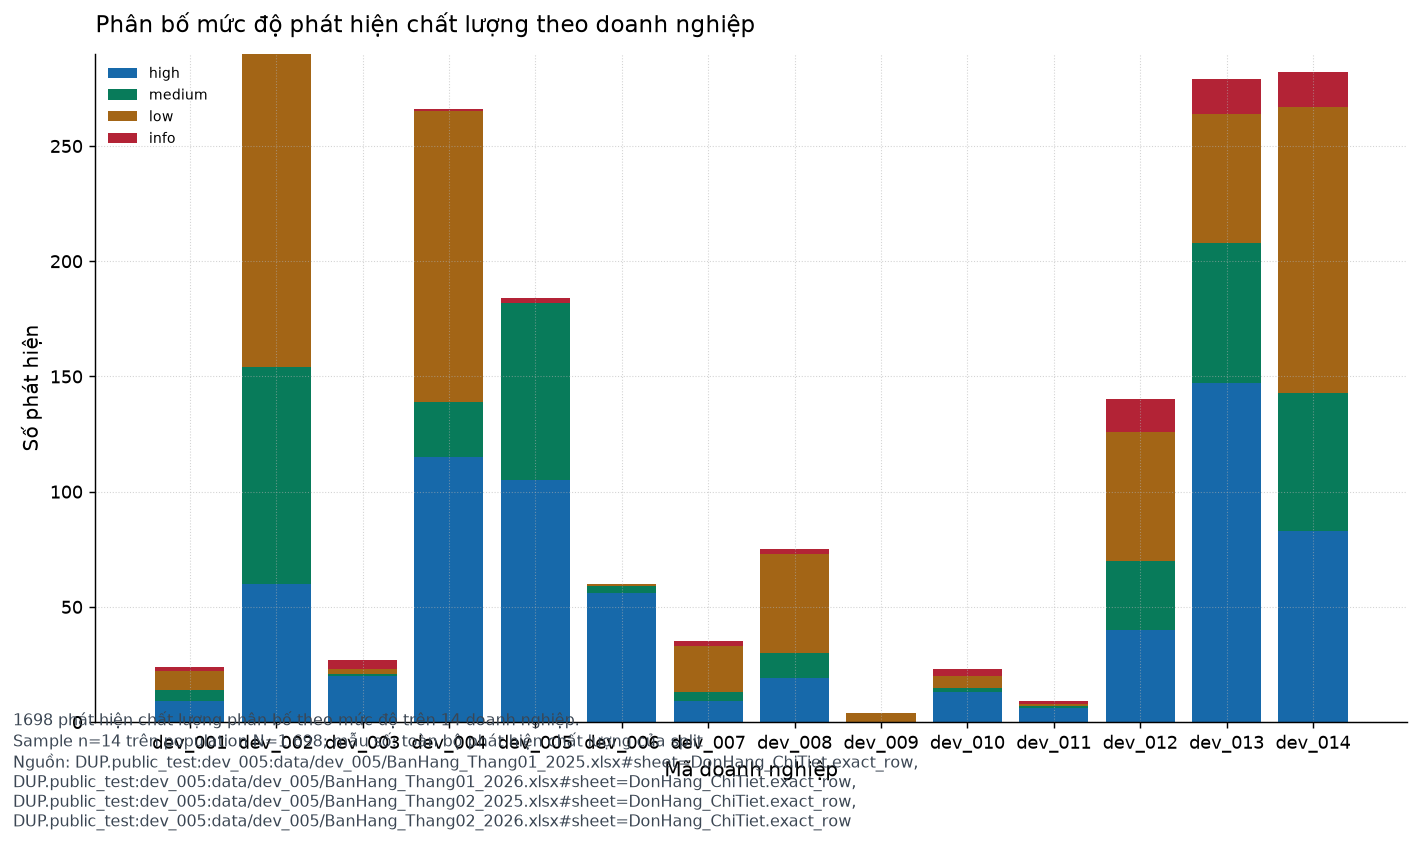


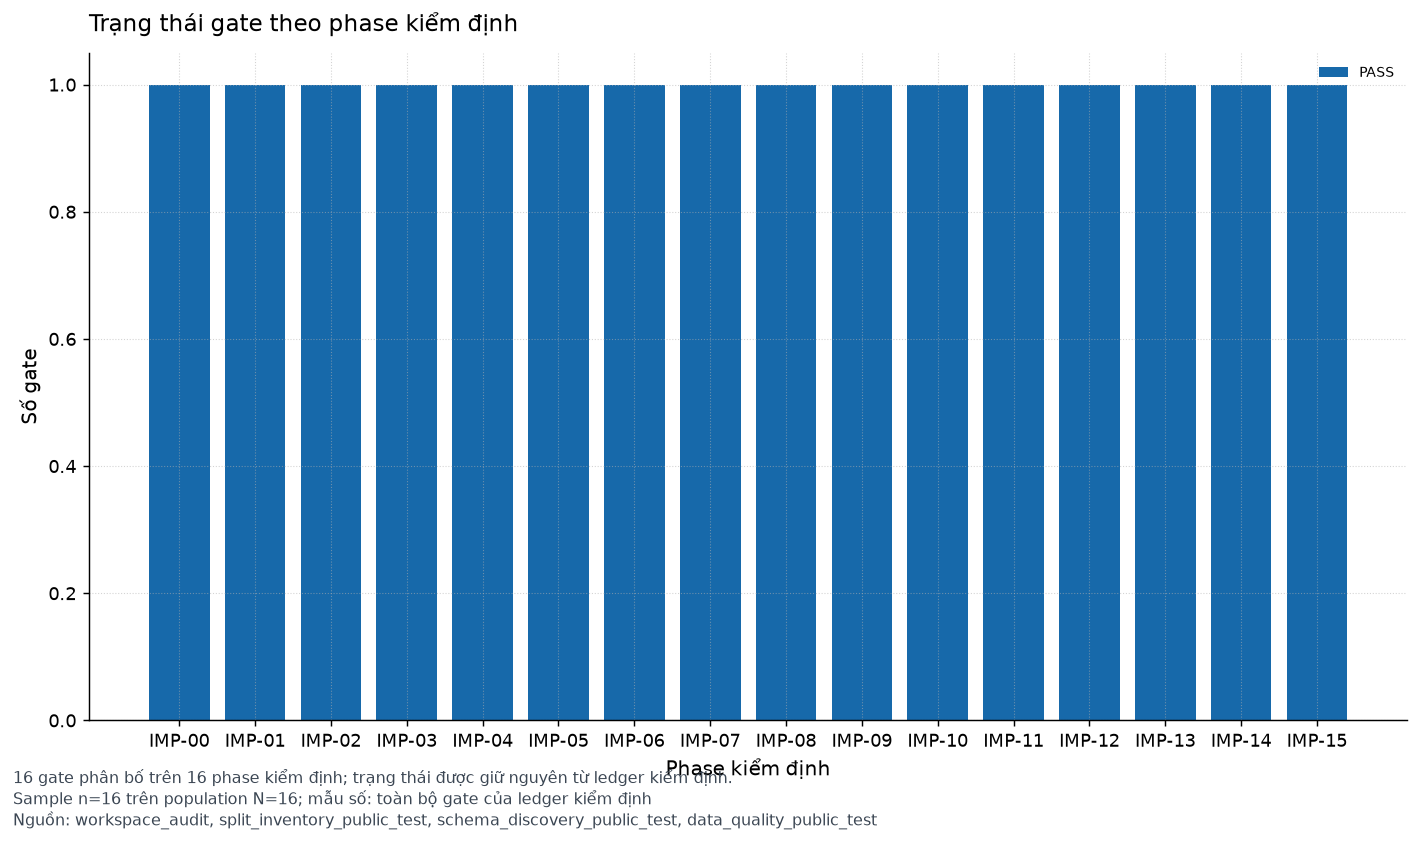

#### Thẻ chuyện `CAT01` — dev_001 (public_test)

1. **Mục tiêu:** Nhóm giá trị nào chiếm ưu thế trong một trường phân loại?
2. **Bối cảnh:** split = public_test; doanh nghiệp = dev_001; nguồn = ('public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = frequency_per_category; quy tắc lọc = count(category) với mẫu số n_valid; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 60
   - n_valid = 60
   - đơn vị = row
   - phương pháp = frequency_per_category
   - công thức = count(category) với mẫu số n_valid
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261116T115457Z_092a846e/analysis/public_test/dev_001/CAT01.png
6. **Nhận xét:**
   - Chưa đủ bằng chứng hoặc điều kiện kiểm chứng để đưa ra nhận xét.
7. **Ý nghĩa:** Mô tả cấu trúc phân phối danh mục kèm mẫu số rõ ràng.
8. **Hạn chế:**
   - association_is_not_causation
   - coverage_and_method_are_reported_with_every_figure
9. **Kết luận:** Kết luận chỉ được ghi khi số liệu kiểm chứng tồn tại; nếu thiếu bằng chứng thì ghi 'Chưa đủ dữ liệu hoặc điều kiện kiểm chứng để đưa ra kết luận.'

*Mức tin cậy: NEEDS_REVIEW; trạng thái: PARTIAL.*

#### Thẻ chuyện `CAT02` — dev_001 (public_test)

1. **Mục tiêu:** Đầu và đuôi phân phối danh mục khác nhau thế nào?
2. **Bối cảnh:** split = public_test; doanh nghiệp = dev_001; nguồn = ('public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = top_k_with_others_bucket; quy tắc lọc = top-k danh mục theo số đếm + Others, tổng bằng n_valid; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 60
   - n_valid = 60
   - đơn vị = row
   - phương pháp = top_k_with_others_bucket
   - công thức = top-k danh mục theo số đếm + Others, tổng bằng n_valid
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261116T115457Z_092a846e/analysis/public_test/dev_001/CAT02.png
6. **Nhận xét:**
   - Chưa đủ bằng chứng hoặc điều kiện kiểm chứng để đưa ra nhận xét.
7. **Ý nghĩa:** Tạo nhóm Others có kiểm soát mà vẫn bảo toàn tổng số đếm.
8. **Hạn chế:**
   - association_is_not_causation
   - coverage_and_method_are_reported_with_every_figure
9. **Kết luận:** Kết luận chỉ được ghi khi số liệu kiểm chứng tồn tại; nếu thiếu bằng chứng thì ghi 'Chưa đủ dữ liệu hoặc điều kiện kiểm chứng để đưa ra kết luận.'

*Mức tin cậy: NEEDS_REVIEW; trạng thái: PARTIAL.*

#### Thẻ chuyện 

In [10]:
_show_table('TBL19', 'public_test')
_show_table('TBL20')

_show_figure('QUAL06', 'public_test', 1)
_show_figure('QUAL08', None, 1)

display(Markdown(run.story_cards_markdown(
    'public_test'
)[:2600]))


## 16. Kết luận khoa học và bàn giao

**Mục tiêu:** Tổng hợp kết luận khoa học, hạn chế đã xác định và dòng dẫn tới từng artifact có hash để tái lập.

**Phương pháp:** Mỗi kết luận gắn mức tin cậy và đường dẫn bằng chứng; thẻ chuyện khoa học đính kèm theo từng nhóm nghiên cứu.

**Cách đọc và hạn chế:** Không có kết luận nào vượt quá phạm vi bằng chứng đã ghi; phần chưa đủ bằng chứng được nêu rõ thay vì bị lược bỏ.



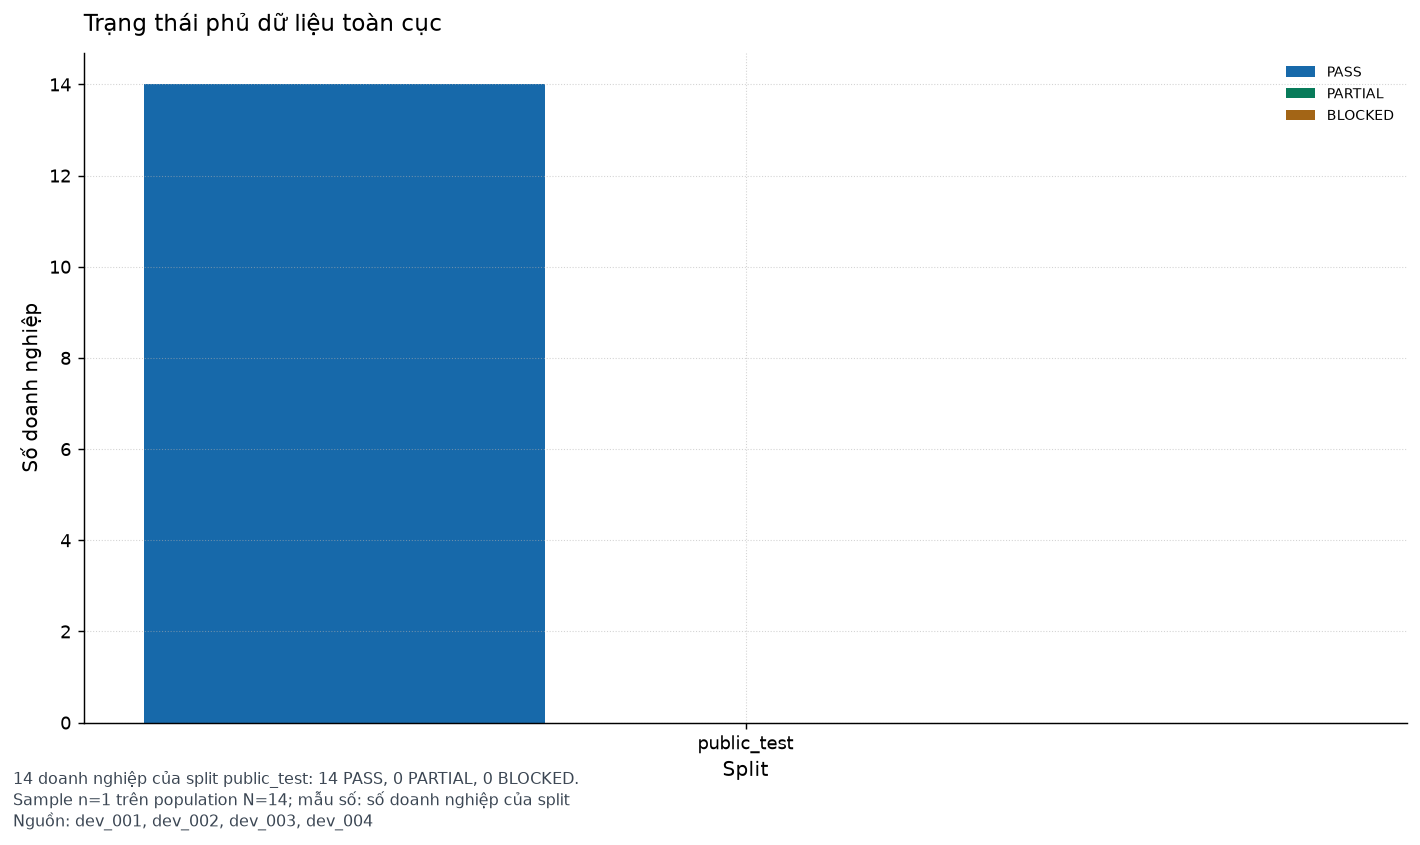

#### Thẻ chuyện `CAT01` — dev_001 (public_test)

1. **Mục tiêu:** Nhóm giá trị nào chiếm ưu thế trong một trường phân loại?
2. **Bối cảnh:** split = public_test; doanh nghiệp = dev_001; nguồn = ('public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = frequency_per_category; quy tắc lọc = count(category) với mẫu số n_valid; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 60
   - n_valid = 60
   - đơn vị = row
   - phương pháp = frequency_per_category
   - công thức = count(category) với mẫu số n_valid
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261116T115457Z_092a846e/analysis/public_test/dev_001/CAT01.png
6. **Nhận xét:**
   - Chưa đủ bằng chứng hoặc điều kiện kiểm chứng để đưa ra nhận xét.
7. **Ý nghĩa:** Mô tả cấu trúc phân phối danh mục kèm mẫu số rõ ràng.
8. **Hạn chế:**
   - association_is_not_causation
   - coverage_and_method_are_reported_with_every_figure
9. **Kết luận:** Kết luận chỉ được ghi khi số liệu kiểm chứng tồn tại; nếu thiếu bằng chứng thì ghi 'Chưa đủ dữ liệu hoặc điều kiện kiểm chứng để đưa ra kết luận.'

*Mức tin cậy: NEEDS_REVIEW; trạng thái: PARTIAL.*

#### Thẻ chuyện `CAT02` — dev_001 (public_test)

1. **Mục tiêu:** Đầu và đuôi phân phối danh mục khác nhau thế nào?
2. **Bối cảnh:** split = public_test; doanh nghiệp = dev_001; nguồn = ('public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = top_k_with_others_bucket; quy tắc lọc = top-k danh mục theo số đếm + Others, tổng bằng n_valid; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 60
   - n_valid = 60
   - đơn vị = row
   - phương pháp = top_k_with_others_bucket
   - công thức = top-k danh mục theo số đếm + Others, tổng bằng n_valid
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261116T115457Z_092a846e/analysis/public_test/dev_001/CAT02.png
6. **Nhận xét:**
   - Chưa đủ bằng chứng hoặc điều kiện kiểm chứng để đưa ra nhận xét.
7. **Ý nghĩa:** Tạo nhóm Others có kiểm soát mà vẫn bảo toàn tổng số đếm.
8. **Hạn chế:**
   - association_is_not_causation
   - coverage_and_method_are_reported_with_every_figure
9. **Kết luận:** Kết luận chỉ được ghi khi số liệu kiểm chứng tồn tại; nếu thiếu bằng chứng thì ghi 'Chưa đủ dữ liệu hoặc điều kiện kiểm chứng để đưa ra kết luận.'

*Mức tin cậy: NEEDS_REVIEW; trạng thái: PARTIAL.*

#### Thẻ chuyện `CAT03` — dev_001 (public_test)

1. **Mục tiêu:** Thành phần danh mục chia đều thế nào?
2. **Bối cảnh:** split = public_test; doanh nghiệp = dev_001; nguồn = ('public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1',); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = category_share_of_valid; quy tắc lọc = count(category) / n_valid; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 60
   - n_valid = 60
   - đơn vị = percent
   - phương pháp = category_share_of_valid
   - công thức = count(category) / n_valid
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261116T115457Z_092a846e/analysis/public_test/dev_001/CAT03.png
6. **Nhận xét:**
   - Chưa đủ bằng chứng hoặc điều kiện kiểm chứng để đưa ra nhận xét.
7. **Ý nghĩa:** Trình bày tỷ trọng với mẫu số nhất quán.
8. **Hạn chế:**
   - association_is_not_causation
   - coverage_and_method_are_reported_with_every_figure
9. **Kết luận:** Kết luận chỉ được ghi khi số liệu kiểm chứng tồn tại; nếu thiếu bằng chứng thì ghi 'Chưa đủ dữ liệu hoặc điều kiện kiểm chứng để đưa ra kết luận.'

*Mức tin cậy: NEEDS_REVIEW; trạng thái: PARTIAL.*

#### Thẻ chuyện `GLOBAL01` — global (public_test)

1. **Mục tiêu:** Doanh nghiệp dùng định dạng lưu trữ nào?
2. **Bối cảnh:** split = public_test; doanh nghiệp = global; nguồn = ('public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx', 'public_test:dev_001:data/dev_001/README.md', 'public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T1_2026.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T2_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T2_2026.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T3_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T3_2026.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T4_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T4_2026.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T5_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T5_2026.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T6_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T7_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T8_2025.xlsx', 'public_test:dev_002:data/dev_002/BanHang_T9_2025.xlsx', 'public_test:dev_002:data/dev_002/DanhSachQuyDoi.xlsx', 'public_test:dev_002:data/dev_002/README.md', 'public_test:dev_003:data/dev_003/BanHang_PhieuThu.xlsx', 'public_test:dev_003:data/dev_003/BanHang_TongHop_2025.xlsx', 'public_test:dev_003:data/dev_003/BanHang_TongHop_2026.xlsx', 'public_test:dev_003:data/dev_003/BaoCaoCa.xlsx', 'public_test:dev_003:data/dev_003/README.md', 'public_test:dev_003:data/dev_003/SoTay_ChiPhi.xlsx', 'public_test:dev_003:data/dev_003/SoTay_NhapHang.xlsx', 'public_test:dev_003:data/dev_003/ton_kho.csv', 'public_test:dev_004:data/dev_004/BangGia.xlsx', 'public_test:dev_004:data/dev_004/DanhMuc.xlsx', 'public_test:dev_004:data/dev_004/README.md', 'public_test:dev_004:data/dev_004/SoBanHang.xlsx', 'public_test:dev_004:data/dev_004/SoGiaoHang.xlsx', 'public_test:dev_004:data/dev_004/SoHanNo.xlsx', 'public_test:dev_004:data/dev_004/SoNhapHang.xlsx', 'public_test:dev_004:data/dev_004/TonKho.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang01_2025.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang01_2026.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang02_2025.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang02_2026.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang03_2025.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang03_2026.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang04_2025.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang04_2026.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang05_2025.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang05_2026.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang06_2025.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang07_2025.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang08_2025.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang09_2025.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang10_2025.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang11_2025.xlsx', 'public_test:dev_005:data/dev_005/BanHang_Thang12_2025.xlsx', 'public_test:dev_005:data/dev_005/DanhSachQuyDoi.xlsx', 'public_test:dev_005:data/dev_005/DanhSachSanPham.xlsx', 'public_test:dev_005:data/dev_005/DanhSachThuoc.xlsx', 'public_test:dev_005:data/dev_005/DonHang_Lo.xlsx', 'public_test:dev_005:data/dev_005/DonNhapHang.xlsx', 'public_test:dev_005:data/dev_005/DonNhapHang_ChiTiet.xlsx', 'public_test:dev_005:data/dev_005/README.md', 'public_test:dev_006:data/dev_006/README.md', 'public_test:dev_006:data/dev_006/pos.sqlite', 'public_test:dev_007:data/dev_007/README.md', 'public_test:dev_007:data/dev_007/chi_tiet_hoa_don.csv', 'public_test:dev_007:data/dev_007/chi_tiet_nhap_hang.csv', 'public_test:dev_007:data/dev_007/danh_muc_hang.csv', 'public_test:dev_008:data/dev_008/ChiTietHoaDon_1.xlsx', 'public_test:dev_008:data/dev_008/ChiTietHoaDon_2.xlsx', 'public_test:dev_008:data/dev_008/ChiTietNhapHang.xlsx', 'public_test:dev_008:data/dev_008/DanhMucHang.xlsx', 'public_test:dev_008:data/dev_008/README.md', 'public_test:dev_009:data/dev_009/README.md', 'public_test:dev_009:data/dev_009/danh_sach_hoa_don.csv', 'public_test:dev_010:data/dev_010/README.md', 'public_test:dev_010:data/dev_010/chi_tiet_don.csv', 'public_test:dev_010:data/dev_010/don_hang.csv', 'public_test:dev_010:data/dev_010/khach_hang.csv', 'public_test:dev_010:data/dev_010/san_pham.csv', 'public_test:dev_010:data/dev_010/thanh_toan.csv', 'public_test:dev_011:data/dev_011/README.md', 'public_test:dev_011:data/dev_011/SoBanHang.xlsx', 'public_test:dev_012:data/dev_012/DanhSachTho.xlsx', 'public_test:dev_012:data/dev_012/README.md', 'public_test:dev_012:data/dev_012/SoSuaXe.xlsx', 'public_test:dev_013:data/dev_013/BanHang_2025.xlsx', 'public_test:dev_013:data/dev_013/BanHang_2026.xlsx', 'public_test:dev_013:data/dev_013/QuanLy.xlsx', 'public_test:dev_013:data/dev_013/README.md', 'public_test:dev_014:data/dev_014/README.md', 'public_test:dev_014:data/dev_014/SoBanHang.xlsx', 'public_test:dev_014:data/dev_014/SoNo.xlsx', 'public_test:dev_014:data/dev_014/ThuMayCu.xlsx', 'public_test:calendar.csv', 'public_test:rulebook.md'); đơn vị quan sát = business_id
3. **Phương pháp:** phương pháp = file_count_by_business_and_format; quy tắc lọc = đếm tệp theo doanh nghiệp và định dạng; xử lý giá trị khuyết = EXCLUDE_FROM_MEASURE_WITH_COUNT; xử lý ngoại lệ = RETAIN_AND_FLAG
4. **Bảng thống kê:**
   - population_n = 96
   - n_valid = 96
   - đơn vị = file
   - phương pháp = file_count_by_business_and_format
   - công thức = đếm tệp theo doanh nghiệp và định dạng
   - lấy mẫu = FULL_AGGREGATION
5. **Biểu đồ:** figures/20261116T115457Z_092a846e/analysis/public_test/global/GLOBAL01.png
6. **Nhận xét:**
   - Chưa đủ bằng chứng hoặc điều kiện kiểm chứng để đưa ra nhận xét.
7. **Ý nghĩa:** Thể hiện tính đa dạng định dạng của bộ dữ liệu.
8. **Hạn chế:**
   - association_is_not_causation
   - coverage_and_method_are_reported_with_every_figure
9. **Kết luận:** Kết luận chỉ được ghi khi số liệu kiểm chứng tồn tại; nếu thiếu bằng chứng thì ghi 'Chưa đủ dữ liệu hoặc điều kiện kiểm chứng để đưa ra kết luận.'

*Mức tin cậy: NEEDS_REVIEW; trạng thái: PARTIAL.*

#### Thẻ chuyện `GLOBAL02` — global (public_test)

1. **Mục tiêu:** Vai trò trường xuất hiện ở doanh nghiệp nào?
2. **Bối cảnh:** split = public_test; doanh nghiệp = global; nguồn = ('public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/Danh sách hàng hóa.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx#sheet=Sheet1', 'public_test:dev_001:data/dev_001/So_chi_tiet_ban_hang.xlsx#sheet=Sheet1', 'public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T10_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T11_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T12_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T1_2025.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T1_2026.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T1_2026.xlsx#sheet=DonHang_ChiTiet', 'public_test:dev_002:data/dev_002/BanHang_T1_2

In [11]:
_show_figure('GLOBAL07', 'public_test', 1)

display(Markdown(run.story_cards_markdown(
    'public_test'
)[:15600]))
